# Visualisasi Infografis CDW 2026
## Sama-Sama Kuliah, Tak Sama Bebannya

Jalankan semua sel dari atas. Simpan notebook bersama lima CSV; di Colab, unggah kelima CSV terlebih dahulu.
Hasil tersimpan di `output_visualisasi_cdw`: PNG 300 dpi, PNG transparan, SVG dengan teks editable, PDF, tabel agregat, dan ZIP aset.
Setiap plot juga disimpan sebagai SVG di folder baru `svg_plot_cdw2026`, terpisah dari folder ekspor sebelumnya.

Urutan: ikon latar → konteks → lintasan → irisan kondisi → model → PETA → mockup JEMBATAN.
Visual tambahan disediakan sebagai alternatif, bukan untuk dimasukkan semuanya dalam satu poster.
Data CDW adalah Real World Fake Data dari universitas anonim. Temuan tidak mewakili seluruh mahasiswa Indonesia.

## 1. Persiapan
Sel ini memasang pustaka hanya jika belum tersedia. Tidak mengubah notebook eksplorasi atau CSV sumber.

In [1]:
import importlib.util
import subprocess
import sys

packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'statsmodels': 'statsmodels'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Pustaka siap.')

Pustaka siap.


In [2]:
from pathlib import Path
from textwrap import fill
from zipfile import ZipFile, ZIP_DEFLATED
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle, Polygon, Arc, FancyArrowPatch
from matplotlib.ticker import FuncFormatter, NullLocator
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Image, Markdown, FileLink

DATA_DIR = None
DPI = 300
TRANSPARENT_PNG = True
SHOW_FIGURES = True

FILES = ['1_profil_mahasiswa_umum.csv', '2_prestasi_mahasiswa.csv',
         '3_generasi_pertama_kuliah.csv', '4_status_sosial_ekonomi.csv',
         '5_riwayat_ipk_semester.csv']
candidates = [Path(DATA_DIR)] if DATA_DIR else [p / "02_Analisis" / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [p / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if all((p / name).is_file() for name in FILES)), None)
if ROOT is None:
    raise FileNotFoundError('Lima CSV belum ditemukan. Unggah ke folder kerja atau isi DATA_DIR.')
OUT = ROOT.parents[1] / '04_Visualisasi' / 'output_visualisasi_cdw'
SVG_OUT = ROOT.parents[1] / '04_Visualisasi' / 'svg_plot_cdw2026'
SVG_OUT.mkdir(parents=True, exist_ok=True)
for folder in ['png', 'png_transparan', 'svg', 'pdf', 'tabel']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

C = {'fg': '#E8710A', 'nonfg': '#1B3A5F', 'risk': '#A8402D', 'green': '#2E8B57',
     'bg': '#FBF7EE', 'ink': '#233044', 'muted': '#627080', 'line': '#D8DCD9',
     'light': '#EDEFEA', 'white': '#FFFFFF'}
GROUP = {1: 'Generasi pertama', 0: 'Bukan generasi pertama'}
COLORS = {1: C['fg'], 0: C['nonfg']}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'text.color': C['ink'], 'axes.labelcolor': C['ink'],
                     'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'axes.facecolor': C['bg'], 'figure.facecolor': C['bg'],
                     'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.spines.bottom': False})
manifest = []
catalog = PdfPages(OUT / 'Katalog_Visual_CDW2026.pdf')

def angka(value, digits=1):
    return f'{value:,.{digits}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def jumlah(value):
    return angka(value, 0)

def persen(value):
    return angka(100 * value) + '%'

def canvas(title, subtitle='', size=(11, 5.8), bottom=0.20):
    fig, ax = plt.subplots(figsize=size)
    fig.subplots_adjust(left=0.10, right=0.93, top=0.77, bottom=bottom)
    fig.text(0.045, 0.94, title, fontsize=19, fontweight='bold', va='top')
    if subtitle:
        fig.text(0.045, 0.865, subtitle, fontsize=10.5, color=C['muted'], va='top')
    return fig, ax

def save_visual(fig, name, section, note, title=None):
    fig.text(0.045, 0.075, note, fontsize=8.5, color=C['muted'], va='top')
    fig.text(0.045, 0.029, 'Sumber: lima CSV CDW 2026. Data fiktif; unit analisis mahasiswa.',
             fontsize=8, color=C['muted'], va='bottom')
    fig.savefig(OUT / 'png' / f'{name}.png', dpi=DPI, bbox_inches='tight', pad_inches=0.22)
    if TRANSPARENT_PNG:
        fig.savefig(OUT / 'png_transparan' / f'{name}.png', dpi=DPI,
                    bbox_inches='tight', pad_inches=0.22, transparent=True)
    fig.savefig(OUT / 'svg' / f'{name}.svg', bbox_inches='tight', pad_inches=0.22, transparent=True)
    fig.savefig(SVG_OUT / f'{name}.svg', format='svg', bbox_inches='tight', pad_inches=0.22, transparent=True)
    fig.savefig(OUT / 'pdf' / f'{name}.pdf', bbox_inches='tight', pad_inches=0.22)
    catalog.savefig(fig, bbox_inches='tight', pad_inches=0.22)
    manifest.append({'nama': name, 'bagian': section, 'judul': title or name,
                     'catatan': note, 'png': f'png/{name}.png', 'svg': f'svg/{name}.svg'})
    if SHOW_FIGURES:
        display(fig)
    plt.close(fig)

def box(ax, x, y, w, h, face=C['white'], edge=C['line'], lw=1.2):
    patch = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.012,rounding_size=0.025',
                           facecolor=face, edgecolor=edge, linewidth=lw)
    ax.add_patch(patch)
    return patch

def clean_percent(ax):
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0f}%'))
    ax.grid(axis='x', alpha=0.35, color=C['line'])
    ax.set_axisbelow(True)

print('Folder data:', ROOT)
print('Folder ekspor:', OUT)
print('Folder SVG baru:', SVG_OUT)

Folder data: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK
Folder ekspor: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\output_visualisasi_cdw
Folder SVG baru: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\svg_plot_cdw2026


## 2. Data dan unit analisis

Sumber: `1_profil_mahasiswa_umum.csv`, `2_prestasi_mahasiswa.csv`, `3_generasi_pertama_kuliah.csv`,
`4_status_sosial_ekonomi.csv`, `5_riwayat_ipk_semester.csv`.
CSV dipisahkan titik koma. Prestasi diringkas per mahasiswa, termasuk peserta, finalis, dan juara.
Status cuti/nonaktif adalah snapshot, bukan prediksi DO. Generasi pertama merujuk pendidikan orang tua, bukan seluruh anggota keluarga.

In [3]:
raw = [pd.read_csv(ROOT / name, sep=';') for name in FILES]
profil, prestasi_raw, generasi, ekonomi, riwayat = raw
for frame in [profil, generasi, ekonomi]:
    assert frame.ID_Mahasiswa.is_unique, 'ID mahasiswa berulang pada tabel utama.'
    assert not frame.ID_Mahasiswa.isna().any(), 'ID mahasiswa kosong.'
    assert set(frame.ID_Mahasiswa) == set(profil.ID_Mahasiswa), 'Cakupan ID tabel utama berbeda.'
assert not riwayat.duplicated(['ID_Mahasiswa', 'Semester_Ke']).any(), 'Riwayat semester berulang.'
assert set(prestasi_raw.ID_Mahasiswa).issubset(set(profil.ID_Mahasiswa))
assert set(riwayat.ID_Mahasiswa) == set(profil.ID_Mahasiswa)

prestasi = prestasi_raw.drop_duplicates().copy()
d = profil.merge(generasi, on='ID_Mahasiswa', validate='one_to_one').merge(
    ekonomi, on='ID_Mahasiswa', suffixes=('_profil', '_ekonomi'), validate='one_to_one')
for col in ['Status_Generasi_Pertama', 'Bekerja_Sambil_Kuliah', 'Status_Penerima_Beasiswa']:
    assert d[col].isin(['Ya', 'Tidak']).all(), f'Kategori tidak dikenal: {col}'
d['fg'] = d.Status_Generasi_Pertama.eq('Ya').astype(int)
d['work'] = d.Bekerja_Sambil_Kuliah.eq('Ya').astype(int)
d['sch'] = d.Status_Penerima_Beasiswa.eq('Ya').astype(int)
d['achievement'] = d.ID_Mahasiswa.isin(prestasi.ID_Mahasiswa).astype(int)
d['winner'] = d.ID_Mahasiswa.isin(prestasi.loc[
    prestasi.Capaian_Prestasi.isin(['Juara 1', 'Juara 2', 'Juara 3']), 'ID_Mahasiswa']).astype(int)
d['natplus'] = d.ID_Mahasiswa.isin(prestasi.loc[
    prestasi.Tingkat_Kegiatan.isin(['Tingkat Nasional', 'Tingkat Internasional']), 'ID_Mahasiswa']).astype(int)
d['interrupted'] = d.Status_Mahasiswa.isin(['Cuti', 'Non-Aktif/DO']).astype(int)
ipk = riwayat.pivot(index='ID_Mahasiswa', columns='Semester_Ke', values='IPK_Kumulatif')
ips = riwayat.pivot(index='ID_Mahasiswa', columns='Semester_Ke', values='IP_Semester')
assert {1, 4}.issubset(ipk.columns)
d = d.merge(ipk[[1, 4]].rename(columns={1: 's1', 4: 's4'}),
            left_on='ID_Mahasiswa', right_index=True, how='left', validate='one_to_one')
d = d.merge(ips[[4]].rename(columns={4: 'ips4'}),
            left_on='ID_Mahasiswa', right_index=True, how='left', validate='one_to_one')
d['gain'] = d.s4 - d.s1
fixed = d.dropna(subset=['s1', 's4']).copy()
low = d.loc[d.Kategori_Ekonomi.eq('Rendah')].copy()
low_fg = low.loc[low.fg.eq(1)].copy()

def summary(frame, groups):
    return frame.groupby(groups, observed=True).agg(
        n=('ID_Mahasiswa', 'size'), ipk=('IPK_Mahasiswa', 'mean'),
        achievement=('achievement', 'mean'), winner=('winner', 'mean'),
        natplus=('natplus', 'mean'), interrupted=('interrupted', 'mean'),
        work_rate=('work', 'mean'), scholarship=('sch', 'mean')).reset_index()

cohort = fixed.groupby('fg').agg(n=('ID_Mahasiswa', 'size'), s1=('s1', 'mean'),
                                s4=('s4', 'mean'), gain=('gain', 'mean'))
intersection = summary(low, ['fg', 'work']).sort_values(['fg', 'work'])
economy_summary = summary(d, ['fg', 'Kategori_Ekonomi'])
gap1 = cohort.loc[0, 's1'] - cohort.loc[1, 's1']
gap4 = cohort.loc[0, 's4'] - cohort.loc[1, 's4']
gain_ratio = cohort.loc[1, 'gain'] / cohort.loc[0, 'gain']
narrowing = 1 - gap4 / gap1
headlines = pd.DataFrame([
    ['Generasi pertama / seluruh mahasiswa', int(d.fg.sum()), len(d)],
    ['Generasi pertama / mahasiswa ekonomi rendah', int(low.fg.sum()), len(low)],
    ['Bekerja / generasi pertama ekonomi rendah', int(low_fg.work.sum()), len(low_fg)]
], columns=['indikator', 'pembilang', 'penyebut'])
headlines['proporsi'] = headlines.pembilang / headlines.penyebut
audit = pd.DataFrame({'sumber': FILES, 'baris_mentah': [len(f) for f in raw]})
display(audit, headlines, cohort, intersection)
for name, frame in {'audit_sumber': audit, 'headline': headlines,
                    'kohort_s1_s4': cohort.reset_index(), 'irisan_ekonomi_rendah': intersection,
                    'capaian_menurut_ekonomi': economy_summary}.items():
    frame.to_csv(OUT / 'tabel' / f'{name}.csv', index=False, encoding='utf-8-sig')

,sumber,baris_mentah
0,1_profil_mahasiswa_umum.csv,5000
1,2_prestasi_mahasiswa.csv,6414
2,3_generasi_pertama_kuliah.csv,5000
3,4_status_sosial_ekonomi.csv,5000
4,5_riwayat_ipk_semester.csv,25099


,indikator,pembilang,penyebut,proporsi
0,Generasi pertama / seluruh mahasiswa,1924,5000,0.384800
1,Generasi pertama / mahasiswa ekonomi rendah,808,1111,0.727273
2,Bekerja / generasi pertama ekonomi rendah,377,808,0.466584


,n,s1,s4,gain
fg,,,,
0,2258,3.157228,3.343353,0.186125
1,1345,2.684520,3.034914,0.350394


,fg,work,n,ipk,achievement,winner,natplus,interrupted,work_rate,scholarship
0,0,0,204,3.293137,0.607843,0.294118,0.215686,0.073529,0.0,0.534314
1,0,1,99,3.180000,0.484848,0.292929,0.161616,0.141414,1.0,0.505051
2,1,0,431,3.029211,0.424594,0.206497,0.146172,0.153132,0.0,0.705336
3,1,1,377,2.805756,0.286472,0.135279,0.068966,0.254642,1.0,0.594164


## 3. Latar belakang: ikon dan teks saja
Ikon dibuat sebagai bentuk vektor sederhana, tanpa grafik data. SVG dapat disunting di aplikasi desain.

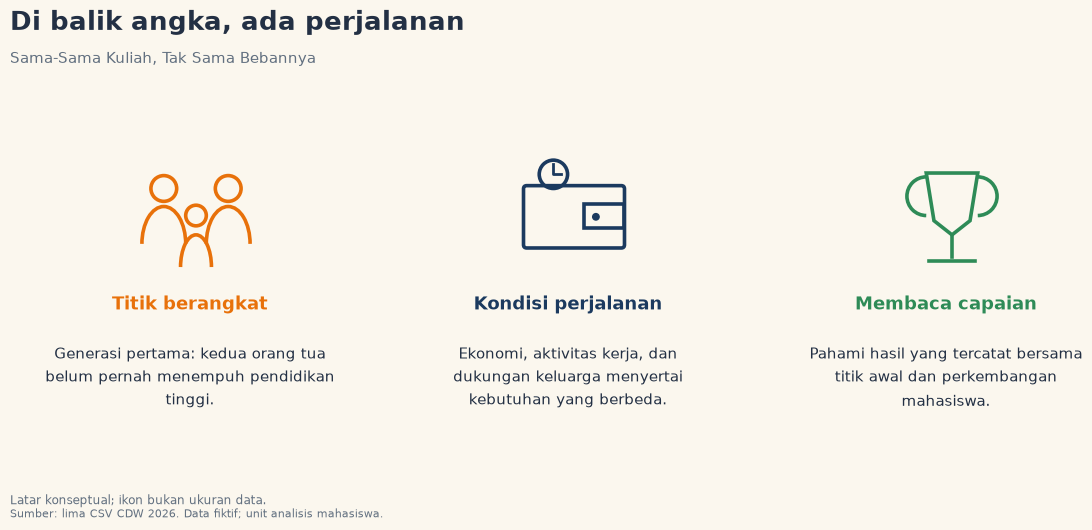

In [4]:
def icon(ax, kind, color):
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal')
    ax.axis('off')
    if kind == 'family':
        for x, y, r in [(0.25, 0.70, 0.10), (0.75, 0.70, 0.10), (0.50, 0.49, 0.08)]:
            ax.add_patch(Circle((x, y), r, fill=False, ec=color, lw=2.6))
        for x, y, w, h in [(0.08, 0.27, 0.34, 0.29), (0.58, 0.27, 0.34, 0.29), (0.38, 0.09, 0.24, 0.25)]:
            ax.add_patch(Arc((x+w/2, y), w, 2*h, theta1=0, theta2=180, ec=color, lw=2.6))
    elif kind == 'wallet':
        box(ax, 0.12, 0.25, 0.76, 0.46, face='none', edge=color, lw=2.6)
        ax.add_patch(Rectangle((0.58, 0.39), 0.31, 0.19, fill=False, ec=color, lw=2.6))
        ax.add_patch(Circle((0.67, 0.48), 0.025, color=color))
        ax.add_patch(Circle((0.34, 0.81), 0.11, fill=False, ec=color, lw=2.6))
        ax.plot([0.34, 0.34, 0.40], [0.89, 0.81, 0.81], color=color, lw=2)
    else:
        ax.add_patch(Polygon([(0.30, 0.82), (0.70, 0.82), (0.64, 0.45),
                              (0.50, 0.34), (0.36, 0.45)], fill=False, ec=color, lw=2.6))
        ax.add_patch(Arc((0.30, 0.64), 0.30, 0.30, theta1=90, theta2=270, ec=color, lw=2.6))
        ax.add_patch(Arc((0.70, 0.64), 0.30, 0.30, theta1=-90, theta2=90, ec=color, lw=2.6))
        ax.plot([0.5, 0.5], [0.34, 0.17], color=color, lw=2.6)
        ax.plot([0.32, 0.68], [0.14, 0.14], color=color, lw=2.6)

fig, ax = canvas('Di balik angka, ada perjalanan',
                 'Sama-Sama Kuliah, Tak Sama Bebannya', size=(12, 5.6))
ax.axis('off')
items = [('family', 'Titik berangkat', 'Generasi pertama: kedua orang tua belum pernah menempuh pendidikan tinggi.', C['fg']),
         ('wallet', 'Kondisi perjalanan', 'Ekonomi, aktivitas kerja, dan dukungan keluarga menyertai kebutuhan yang berbeda.', C['nonfg']),
         ('trophy', 'Membaca capaian', 'Pahami hasil yang tercatat bersama titik awal dan perkembangan mahasiswa.', C['green'])]
for i, (kind, title, text, color) in enumerate(items):
    x = 0.055 + i * 0.315
    small = fig.add_axes([x+0.075, 0.46, 0.14, 0.23])
    icon(small, kind, color)
    fig.text(x+0.14, 0.405, title, ha='center', weight='bold', fontsize=13, color=color)
    fig.text(x+0.14, 0.345, fill(text, 34), ha='center', va='top', fontsize=11, linespacing=1.5)
save_visual(fig, '00_latar_ikon_teks', 'Latar belakang',
            'Latar konseptual; ikon bukan ukuran data.', 'Di balik angka, ada perjalanan')

## 4. Pembahasan: konteks sederhana
Tiga angka besar memiliki penyebut berbeda. Jangan menjumlahkan persentasenya.

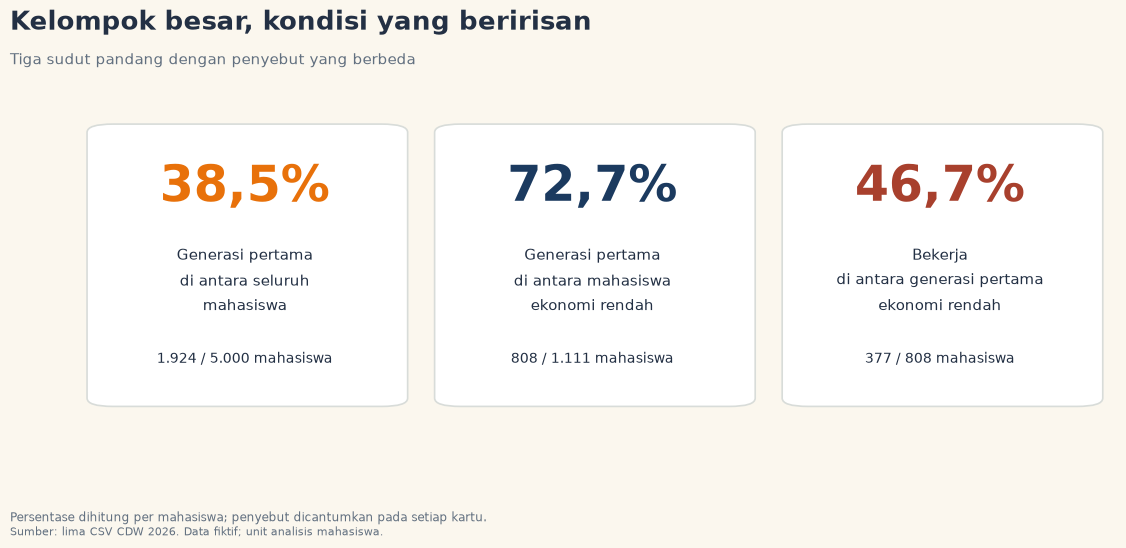

In [5]:
fig, ax = canvas('Kelompok besar, kondisi yang beririsan',
                 'Tiga sudut pandang dengan penyebut yang berbeda', size=(12.5, 5.8))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis('off')
labels = ['Generasi pertama\ndi antara seluruh\nmahasiswa',
          'Generasi pertama\ndi antara mahasiswa\nekonomi rendah',
          'Bekerja\ndi antara generasi pertama\nekonomi rendah']
for i, row in headlines.iterrows():
    x = i * 0.335
    color = [C['fg'], C['nonfg'], C['risk']][i]
    box(ax, x+0.02, 0.11, 0.285, 0.83)
    ax.text(x+0.16, 0.72, persen(row.proporsi), ha='center', fontsize=35, weight='bold', color=color)
    ax.text(x+0.16, 0.48, labels[i], ha='center', va='center', fontsize=11, linespacing=1.6)
    ax.text(x+0.16, 0.23, f'{jumlah(row.pembilang)} / {jumlah(row.penyebut)} mahasiswa', ha='center', fontsize=10)
save_visual(fig, '01_konteks_angka_besar', 'Pembahasan',
            'Persentase dihitung per mahasiswa; penyebut dicantumkan pada setiap kartu.', 'Konteks utama')

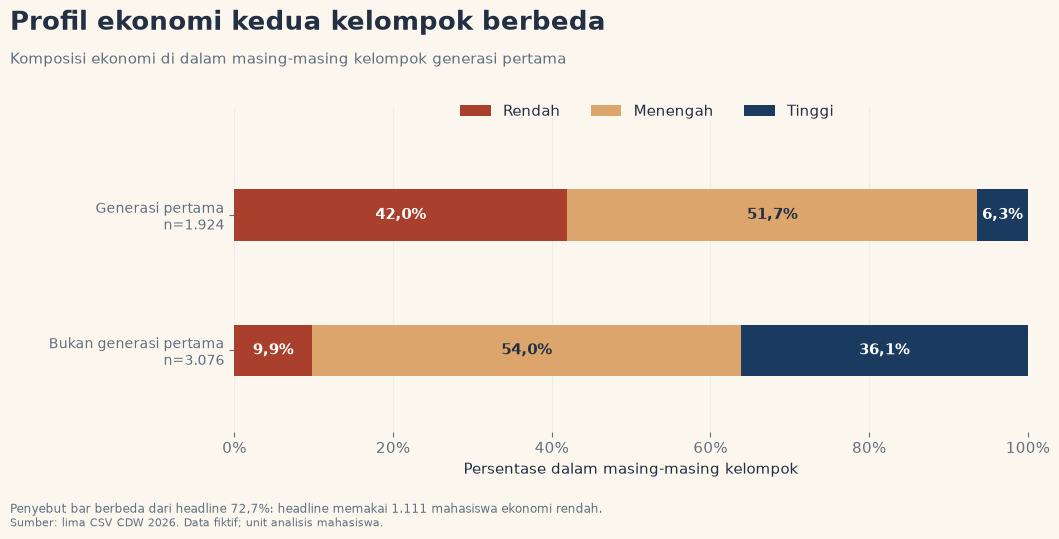

In [6]:
econ_order = ['Rendah', 'Menengah', 'Tinggi']
econ_counts = pd.crosstab(d.fg, d.Kategori_Ekonomi).reindex(index=[1, 0], columns=econ_order, fill_value=0)
econ_pct = econ_counts.div(econ_counts.sum(axis=1), axis=0) * 100
fig, ax = canvas('Profil ekonomi kedua kelompok berbeda',
                 'Komposisi ekonomi di dalam masing-masing kelompok generasi pertama', size=(11.5, 5.7))
econ_colors = [C['risk'], '#DCA56B', C['nonfg']]
left = np.zeros(2)
for label, color in zip(econ_order, econ_colors):
    values = econ_pct[label].to_numpy()
    ax.barh([1, 0], values, left=left, height=0.38, color=color, label=label)
    for y, start, value in zip([1, 0], left, values):
        ax.text(start+value/2, y, angka(value)+'%', ha='center', va='center',
                color=C['white'] if label != 'Menengah' else C['ink'], fontsize=11, weight='bold')
    left += values
ax.set_yticks([1, 0], [f'{GROUP[g]}\nn={jumlah(econ_counts.loc[g].sum())}' for g in [1, 0]], fontsize=10)
clean_percent(ax)
ax.set_ylim(-0.6, 1.8)
ax.legend(loc='upper center', bbox_to_anchor=(0.52, 1.05), ncol=3, frameon=False)
ax.set_xlabel('Persentase dalam masing-masing kelompok')
fig.subplots_adjust(left=0.24)
save_visual(fig, '02_ekonomi_stacked_100', 'Pembahasan',
            f'Penyebut bar berbeda dari headline {persen(low.fg.mean())}: headline memakai {jumlah(len(low))} mahasiswa ekonomi rendah.',
            'Komposisi ekonomi')
econ_pct.reset_index().to_csv(OUT / 'tabel' / 'komposisi_ekonomi_persen.csv', index=False, encoding='utf-8-sig')

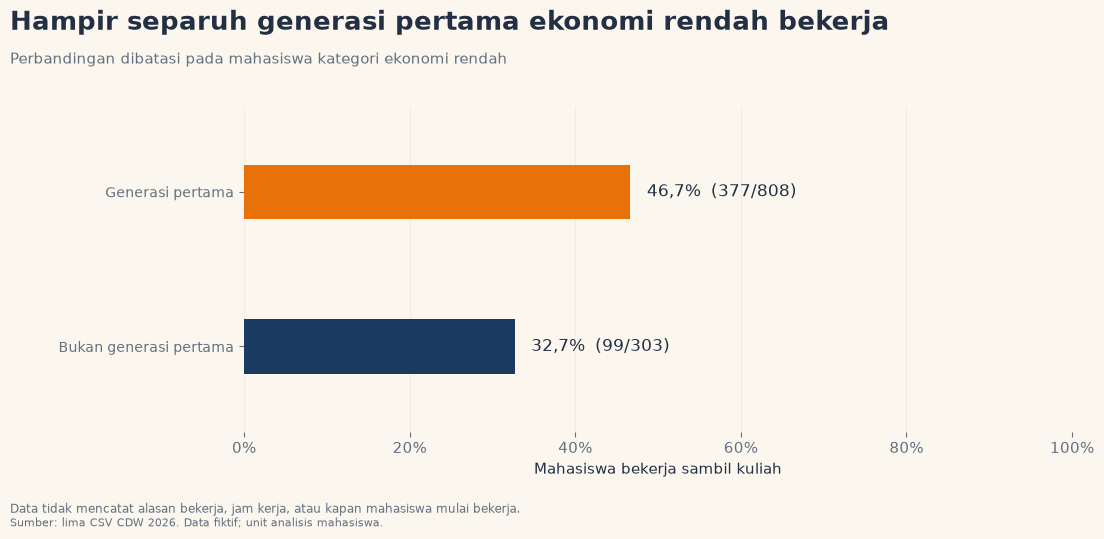

In [7]:
work_summary = low.groupby('fg').agg(n=('ID_Mahasiswa', 'size'), bekerja=('work', 'sum'), rate=('work', 'mean')).reindex([1, 0])
fig, ax = canvas('Hampir separuh generasi pertama ekonomi rendah bekerja',
                 'Perbandingan dibatasi pada mahasiswa kategori ekonomi rendah', size=(12, 5.7))
for y, g in zip([1, 0], [1, 0]):
    row = work_summary.loc[g]
    ax.barh(y, 100*row.rate, height=0.35, color=COLORS[g])
    ax.text(100*row.rate+2, y, f'{persen(row.rate)}  ({jumlah(row.bekerja)}/{jumlah(row.n)})', va='center', fontsize=12)
ax.set_yticks([1, 0], [GROUP[1], GROUP[0]], fontsize=10)
ax.set_ylim(-0.55, 1.55)
ax.set_xlabel('Mahasiswa bekerja sambil kuliah')
clean_percent(ax)
fig.subplots_adjust(left=0.24)
save_visual(fig, '03_bekerja_ekonomi_rendah', 'Pembahasan',
            'Data tidak mencatat alasan bekerja, jam kerja, atau kapan mahasiswa mulai bekerja.', 'Bekerja pada ekonomi rendah')
work_summary.reset_index().to_csv(OUT / 'tabel' / 'bekerja_ekonomi_rendah.csv', index=False, encoding='utf-8-sig')

## 5. Analisis lintasan: kohort tetap semester 1 dan 4
Kenaikan tidak otomatis membuktikan ketangguhan atau efek intervensi. Nilai awal dan batas atas IPK perlu dipertimbangkan.

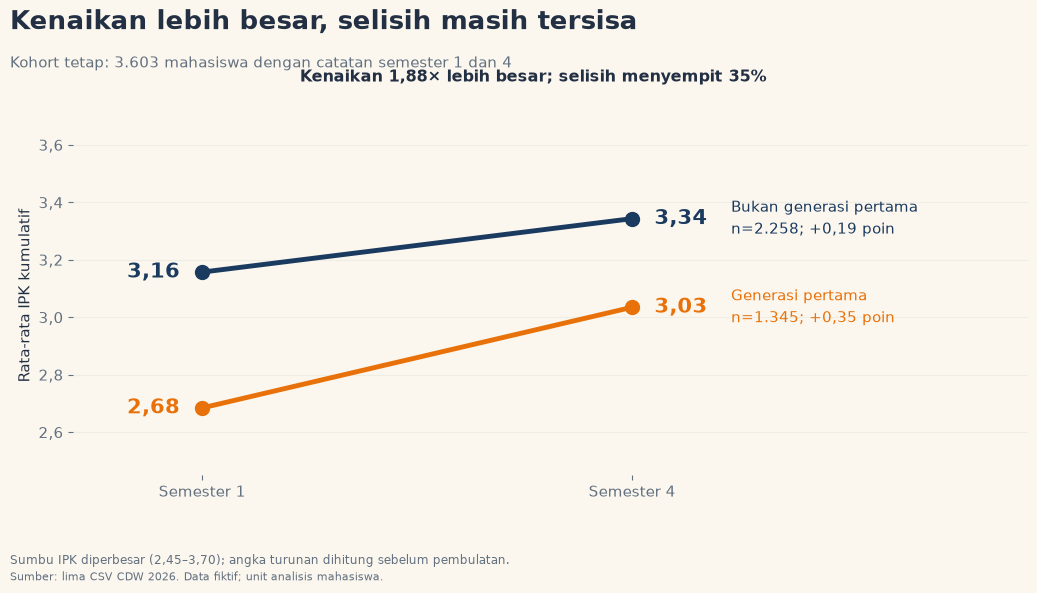

In [8]:
fig, ax = canvas('Kenaikan lebih besar, selisih masih tersisa',
                 f'Kohort tetap: {jumlah(len(fixed))} mahasiswa dengan catatan semester 1 dan 4', size=(11.5, 6.3))
for g in [0, 1]:
    row = cohort.loc[g]
    values = [row.s1, row.s4]
    ax.plot([0, 1], values, color=COLORS[g], lw=3.5, marker='o', ms=10)
    for x, value in zip([0, 1], values):
        ax.annotate(angka(value, 2), (x, value), xytext=(-16 if x == 0 else 16, 0),
                    textcoords='offset points', ha='right' if x == 0 else 'left',
                    va='center', fontsize=15, weight='bold', color=COLORS[g])
    ax.text(1.23, row.s4, f'{GROUP[g]}\nn={jumlah(row.n)}; +{angka(row.gain, 2)} poin',
            va='center', fontsize=10.5, color=COLORS[g], linespacing=1.5)
ax.set(xlim=(-0.30, 1.92), ylim=(2.45, 3.7), ylabel='Rata-rata IPK kumulatif')
ax.set_xticks([0, 1], ['Semester 1', 'Semester 4'])
ax.grid(axis='y', alpha=0.35, color=C['line'])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: angka(x, 1)))
fig.text(0.50, 0.825, f'Kenaikan {angka(gain_ratio, 2)}× lebih besar; selisih menyempit {angka(100*narrowing, 0)}%',
         ha='center', fontsize=11.5, weight='bold')
save_visual(fig, '04_slope_ipk_kohort_tetap', 'Analisis inti',
            'Sumbu IPK diperbesar (2,45–3,70); angka turunan dihitung sebelum pembulatan.', 'Lintasan IPK kohort tetap')

## 6. Analisis irisan: matriks 2×2
Empat kelompok pada ekonomi rendah, bukan tangga sebab-akibat. Setiap kartu memiliki penyebut sendiri.

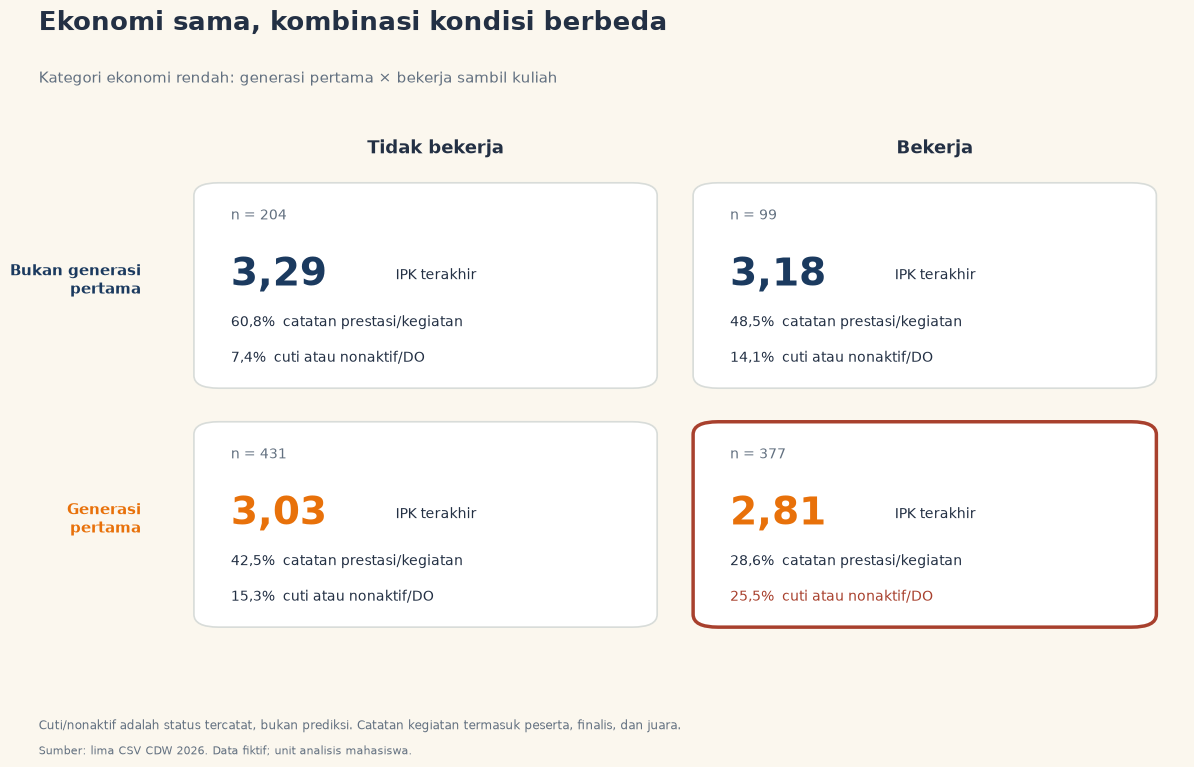

In [9]:
fig, ax = canvas('Ekonomi sama, kombinasi kondisi berbeda',
                 'Kategori ekonomi rendah: generasi pertama × bekerja sambil kuliah', size=(12.8, 8.2), bottom=0.17)
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis('off')
fig.subplots_adjust(left=0.16, right=0.94, top=0.79)
for col, work in enumerate([0, 1]):
    ax.text(0.25+col*0.5, 0.96, ['Tidak bekerja', 'Bekerja'][col], ha='center', fontsize=13, weight='bold')
for row_index, fg in enumerate([0, 1]):
    y = 0.51 if row_index == 0 else 0.04
    ax.text(-0.045, y+0.20, 'Bukan generasi\npertama' if fg == 0 else 'Generasi\npertama',
            ha='right', va='center', fontsize=11, color=COLORS[fg], weight='bold')
    for col, work in enumerate([0, 1]):
        row = intersection.loc[intersection.fg.eq(fg) & intersection.work.eq(work)].iloc[0]
        x = 0.02+col*0.5
        edge = C['risk'] if fg == 1 and work == 1 else C['line']
        box(ax, x, y, 0.44, 0.38, edge=edge, lw=2.5 if fg == 1 and work == 1 else 1.2)
        ax.text(x+0.025, y+0.32, 'n = '+jumlah(row.n), fontsize=10, color=C['muted'])
        ax.text(x+0.025, y+0.19, angka(row.ipk, 2), fontsize=28, weight='bold', color=COLORS[fg])
        ax.text(x+0.19, y+0.21, 'IPK terakhir', fontsize=10, va='center')
        ax.text(x+0.025, y+0.11, persen(row.achievement)+'  catatan prestasi/kegiatan', fontsize=10)
        ax.text(x+0.025, y+0.04, persen(row.interrupted)+'  cuti atau nonaktif/DO', fontsize=10, color=edge if edge==C['risk'] else C['ink'])
save_visual(fig, '05_matriks_irisan_2x2', 'Analisis inti',
            'Cuti/nonaktif adalah status tercatat, bukan prediksi. Catatan kegiatan termasuk peserta, finalis, dan juara.',
            'Matriks irisan ekonomi rendah')

## 7. Model terkontrol dan forest plot

OLS memakai standard error HC3; logistik binomial memakai kovarians sandwich HC0. Interval kepercayaan 95% menggunakan pendekatan normal.
Model utama menambahkan kategori lama studi. Model nilai semester 4 mempertimbangkan nilai semester 1 dan angkatan.
Outcome model terakhir adalah **IP semester 4**, bukan IPK kumulatif. OR bukan persentase probabilitas.

In [10]:
def model_frame(data, outcome, extra):
    nums = ['fg', 'work', 'sch', 'Tingkat_Dukungan_Keluarga', 'Jumlah_Tanggungan_Keluarga']
    cats = ['Kategori_Ekonomi', 'Kategori_UKT', 'Jenis_Kelamin', 'Fakultas']
    if extra == 'duration':
        cats += ['Masa_Studi_Semester']
    if extra == 'baseline':
        nums += ['s1']
        cats += ['Angkatan']
    subset = data.dropna(subset=[outcome, *nums, *cats]).copy()
    x = subset[nums].astype(float)
    for col in cats:
        x = pd.concat([x, pd.get_dummies(subset[col].astype('category'),
                       prefix=col, drop_first=True, dtype=float)], axis=1)
    x = sm.add_constant(x, has_constant='add')
    assert np.linalg.matrix_rank(x.to_numpy()) == x.shape[1], 'Matriks model tidak full rank.'
    return subset[outcome].astype(float), x

def fit_ols(data, outcome='IPK_Mahasiswa', extra='duration'):
    y, x = model_frame(data, outcome, extra)
    return sm.OLS(y, x).fit(cov_type='HC3', use_t=False)

def fit_logistic(data, extra='duration'):
    y, x = model_frame(data, 'achievement', extra)
    fit = sm.GLM(y, x, family=sm.families.Binomial()).fit(cov_type='HC0')
    assert fit.converged, 'Regresi logistik belum konvergen.'
    return fit

ols_original = fit_ols(d, extra='original')
logit_original = fit_logistic(d, extra='original')
ols_duration = fit_ols(d)
logit_duration = fit_logistic(d)
ols_baseline = fit_ols(fixed, outcome='ips4', extra='baseline')

def coefficients(fit, name, odds=False):
    ci = fit.conf_int()
    result = pd.DataFrame({'term': fit.params.index, 'estimate': fit.params.to_numpy(),
                          'low': ci.iloc[:, 0].to_numpy(), 'high': ci.iloc[:, 1].to_numpy(),
                          'p': fit.pvalues.to_numpy()})
    if odds:
        result[['estimate', 'low', 'high']] = np.exp(result[['estimate', 'low', 'high']])
    result['model'] = name
    result['n'] = int(fit.nobs)
    result['ukuran'] = 'Odds ratio' if odds else 'Koefisien IP/IPK'
    return result

model_tables = [coefficients(ols_original, 'OLS notebook'),
                coefficients(logit_original, 'Logistik notebook', True),
                coefficients(ols_duration, 'OLS + lama studi'),
                coefficients(logit_duration, 'Logistik + lama studi', True),
                coefficients(ols_baseline, 'IP semester 4 + baseline')]
model_results = pd.concat(model_tables, ignore_index=True)
model_results.to_csv(OUT / 'tabel' / 'koefisien_semua_model.csv', index=False, encoding='utf-8-sig')
model_info = pd.DataFrame([
    ['OLS notebook', int(ols_original.nobs), ols_original.rsquared, 'HC3'],
    ['OLS + lama studi', int(ols_duration.nobs), ols_duration.rsquared, 'HC3'],
    ['IP semester 4 + baseline', int(ols_baseline.nobs), ols_baseline.rsquared, 'HC3']
], columns=['model', 'n', 'r_squared', 'standard_error'])
model_info.to_csv(OUT / 'tabel' / 'ringkasan_model_ols.csv', index=False, encoding='utf-8-sig')
display(model_info, model_results.loc[model_results.term.isin(['fg', 'work', 'sch'])])

,model,n,r_squared,standard_error
0,OLS notebook,5000,0.228378,HC3
1,OLS + lama studi,5000,0.323909,HC3
2,IP semester 4 + baseline,3603,0.463681,HC3


,term,estimate,low,high,p,model,n,ukuran
1,fg,-0.253010,-0.280224,-0.225796,3.460342e-74,OLS notebook,5000,Koefisien IP/IPK
2,work,-0.166420,-0.195341,-0.137499,1.681055e-29,OLS notebook,5000,Koefisien IP/IPK
3,sch,0.183820,0.158295,0.209345,3.070960e-45,OLS notebook,5000,Koefisien IP/IPK
31,fg,0.522159,0.455498,0.598577,1.115624e-20,Logistik notebook,5000,Odds ratio
32,work,0.595833,0.517244,0.686364,7.238528e-13,Logistik notebook,5000,Odds ratio
33,sch,1.359581,1.187258,1.556915,8.902915e-06,Logistik notebook,5000,Odds ratio
61,fg,-0.242133,-0.267392,-0.216875,9.312694e-79,OLS + lama studi,5000,Koefisien IP/IPK
62,work,-0.143105,-0.169878,-0.116332,1.108709e-25,OLS + lama studi,5000,Koefisien IP/IPK
63,sch,0.174064,0.149819,0.198309,5.698475e-45,OLS + lama studi,5000,Koefisien IP/IPK
101,fg,0.496921,0.428772,0.575901,1.511232e-20,Logistik + lama studi,5000,Odds ratio


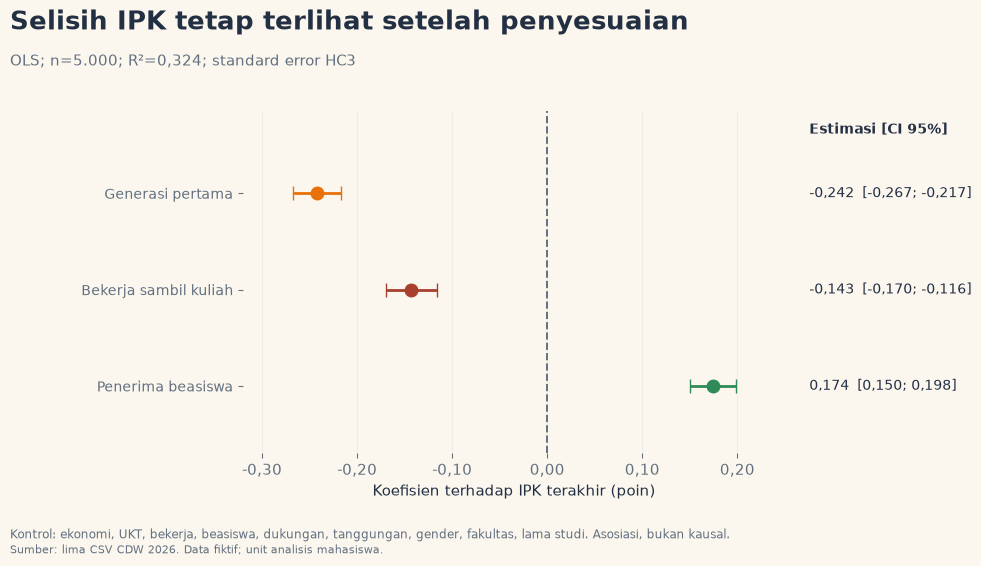

In [11]:
TERM_LABEL = {'fg': 'Generasi pertama', 'work': 'Bekerja sambil kuliah', 'sch': 'Penerima beasiswa'}
TERM_COLOR = {'fg': C['fg'], 'work': C['risk'], 'sch': C['green']}

def forest(frame, title, subtitle, name, xlabel, reference, limits, note, log_scale=False):
    rows = frame.set_index('term').loc[['fg', 'work', 'sch']]
    fig, ax = canvas(title, subtitle, size=(12.6, 6.0))
    fig.subplots_adjust(left=0.23, right=0.66)
    ax.axvline(reference, color=C['muted'], ls='--', lw=1.4)
    for y, (term, row) in zip([2, 1, 0], rows.iterrows()):
        ax.errorbar(row.estimate, y, xerr=[[row.estimate-row.low], [row.high-row.estimate]],
                    fmt='o', color=TERM_COLOR[term], capsize=5, ms=9, lw=2)
        ax.text(1.045, y, f'{angka(row.estimate, 3)}  [{angka(row.low, 3)}; {angka(row.high, 3)}]',
                transform=ax.get_yaxis_transform(), va='center', fontsize=10)
    ax.text(1.045, 2.62, 'Estimasi [CI 95%]', transform=ax.get_yaxis_transform(), fontsize=10, weight='bold')
    ax.set_yticks([2, 1, 0], [TERM_LABEL[t] for t in rows.index], fontsize=10)
    ax.set(xlim=limits, ylim=(-0.7, 2.85), xlabel=xlabel)
    if log_scale:
        ax.set_xscale('log')
        ax.set_xticks([0.4, 0.5, 0.75, 1, 1.5, 2])
        ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: angka(x, 2)))
    ax.grid(axis='x', color=C['line'], alpha=0.35)
    save_visual(fig, name, 'Analisis inti', note, title)

forest(model_tables[2], 'Selisih IPK tetap terlihat setelah penyesuaian',
       f'OLS; n={jumlah(ols_duration.nobs)}; R²={angka(ols_duration.rsquared, 3)}; standard error HC3',
       '06_forest_ipk_terkontrol', 'Koefisien terhadap IPK terakhir (poin)', 0, (-0.32, 0.25),
       'Kontrol: ekonomi, UKT, bekerja, beasiswa, dukungan, tanggungan, gender, fakultas, lama studi. Asosiasi, bukan kausal.')

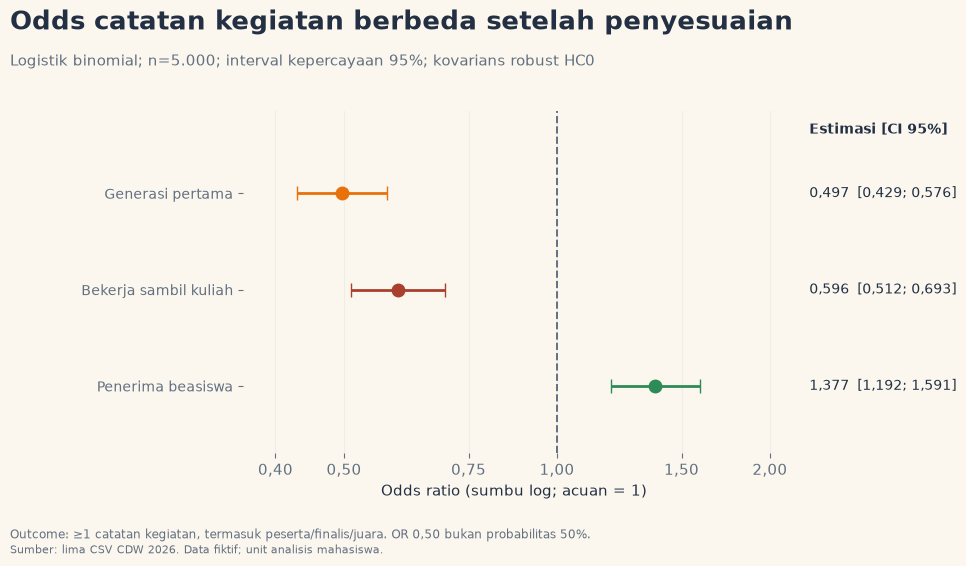

In [12]:
forest(model_tables[3], 'Odds catatan kegiatan berbeda setelah penyesuaian',
       f'Logistik binomial; n={jumlah(logit_duration.nobs)}; interval kepercayaan 95%; kovarians robust HC0',
       '07_forest_odds_prestasi', 'Odds ratio (sumbu log; acuan = 1)', 1, (0.36, 2.1),
       'Outcome: ≥1 catatan kegiatan, termasuk peserta/finalis/juara. OR 0,50 bukan probabilitas 50%.', log_scale=True)

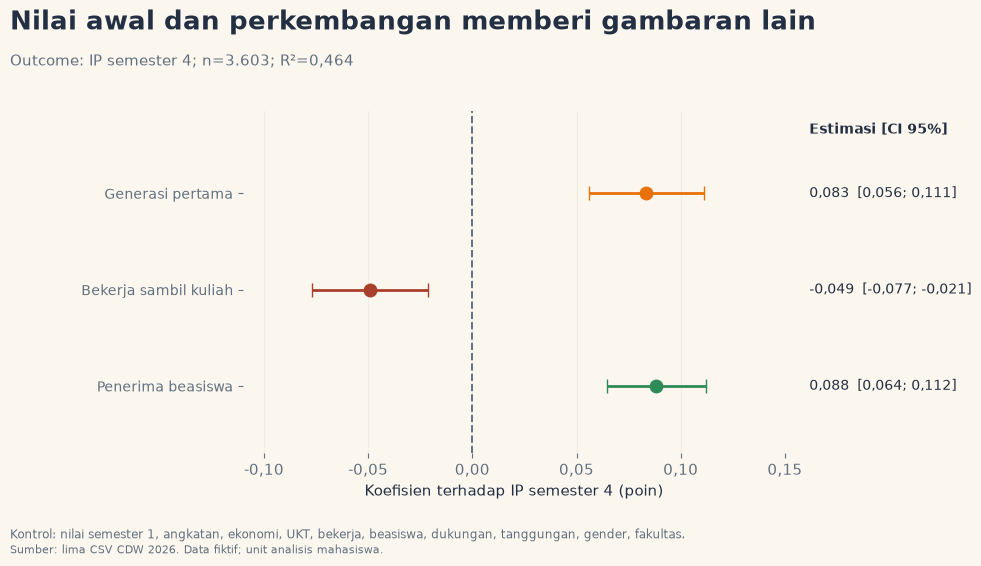

In [13]:
forest(model_tables[4], 'Nilai awal dan perkembangan memberi gambaran lain',
       f'Outcome: IP semester 4; n={jumlah(ols_baseline.nobs)}; R²={angka(ols_baseline.rsquared, 3)}',
       '08_forest_ip_semester4_baseline', 'Koefisien terhadap IP semester 4 (poin)', 0, (-0.11, 0.15),
       'Kontrol: nilai semester 1, angkatan, ekonomi, UKT, bekerja, beasiswa, dukungan, tanggungan, gender, fakultas.')

## 8. Jembatan strategi: PETA
Diagram berikut adalah strategi yang diusulkan, bukan hasil model sebab-akibat.

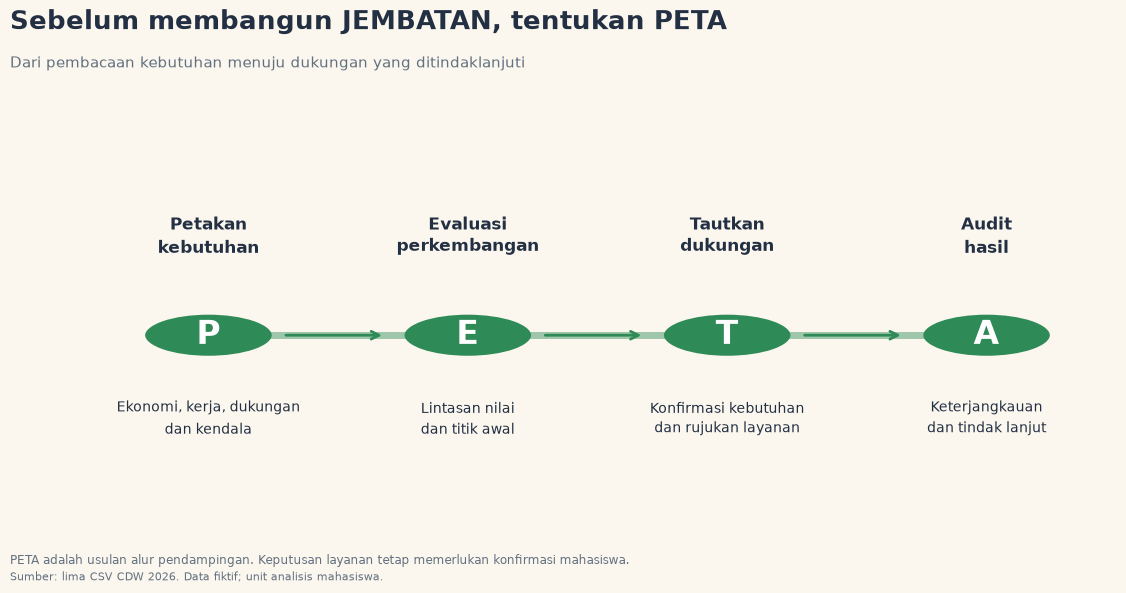

In [14]:
fig, ax = canvas('Sebelum membangun JEMBATAN, tentukan PETA',
                 'Dari pembacaan kebutuhan menuju dukungan yang ditindaklanjuti', size=(12.5, 6.3))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis('off')
ax.plot([0.07, 0.93], [0.39, 0.39], color=C['green'], lw=5, alpha=0.45)
steps = [('P', 'Petakan kebutuhan', 'Ekonomi, kerja, dukungan\ndan kendala'),
         ('E', 'Evaluasi perkembangan', 'Lintasan nilai\ndan titik awal'),
         ('T', 'Tautkan dukungan', 'Konfirmasi kebutuhan\ndan rujukan layanan'),
         ('A', 'Audit hasil', 'Keterjangkauan\ndan tindak lanjut')]
for i, (letter, title, text) in enumerate(steps):
    x = 0.125+i*0.25
    ax.add_patch(Circle((x, 0.39), 0.063, facecolor=C['green'], edgecolor=C['bg'], lw=3))
    ax.text(x, 0.39, letter, ha='center', va='center', fontsize=24, weight='bold', color=C['white'])
    ax.text(x, 0.67, title.replace(' ', '\n', 1), ha='center', va='center', fontsize=12, weight='bold', linespacing=1.4)
    ax.text(x, 0.16, text, ha='center', va='center', fontsize=10, linespacing=1.5)
    if i < 3:
        ax.add_patch(FancyArrowPatch((x+0.072, 0.39), (x+0.17, 0.39), arrowstyle='->',
                                    mutation_scale=14, color=C['green'], lw=2))
save_visual(fig, '09_strategi_peta', 'Jembatan strategi',
            'PETA adalah usulan alur pendampingan. Keputusan layanan tetap memerlukan konfirmasi mahasiswa.', 'Strategi PETA')

## 9. Solusi: mockup JEMBATAN
Mockup statis, bukan aplikasi operasional. Angka kelompok berasal dari CSV; layanan merupakan contoh antarmuka.
Waktu respons dan penggunaan layanan belum tersedia pada dataset, sehingga tidak diberi angka rekaan.

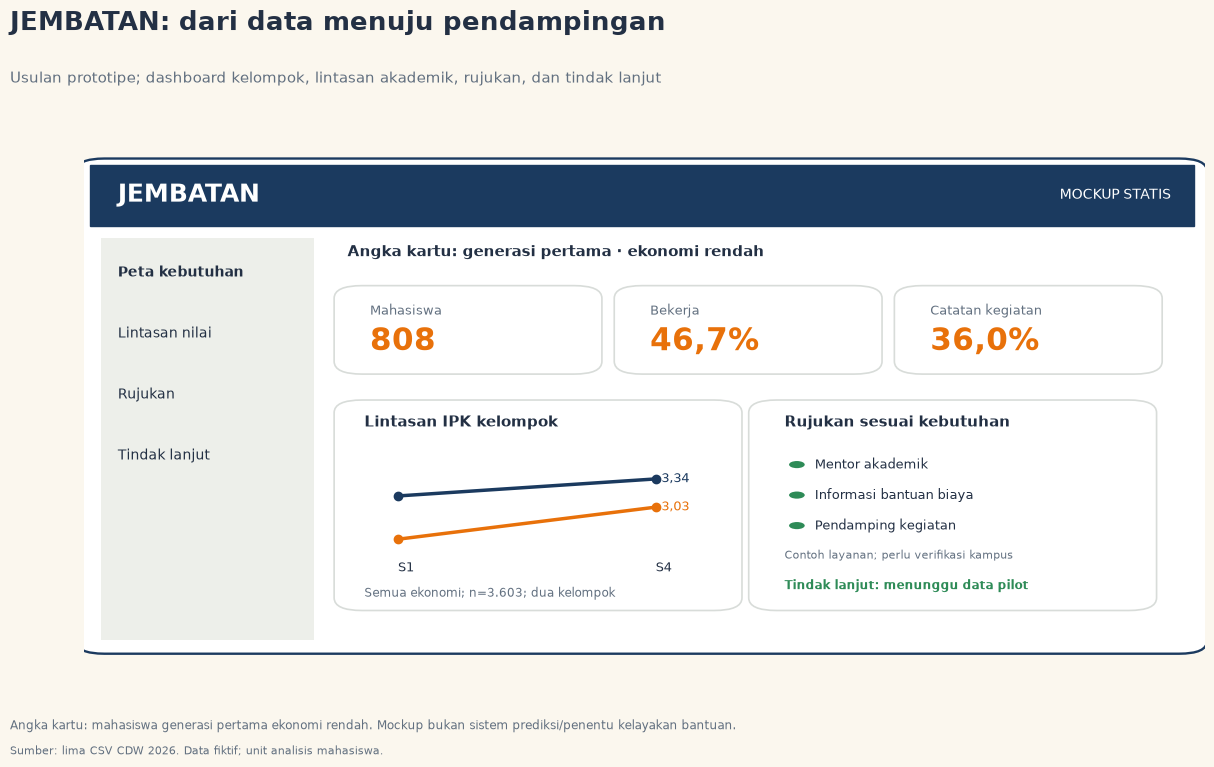

In [15]:
fig, ax = canvas('JEMBATAN: dari data menuju pendampingan',
                 'Usulan prototipe; dashboard kelompok, lintasan akademik, rujukan, dan tindak lanjut', size=(13.5, 8.2), bottom=0.15)
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis('off')
box(ax, 0.005, 0.02, 0.985, 0.95, edge=C['nonfg'], lw=1.7)
ax.add_patch(Rectangle((0.005, 0.85), 0.985, 0.12, color=C['nonfg']))
ax.text(0.03, 0.91, 'JEMBATAN', color=C['white'], fontsize=18, weight='bold', va='center')
ax.text(0.97, 0.91, 'MOCKUP STATIS', color=C['white'], fontsize=10, ha='right', va='center')
ax.add_patch(Rectangle((0.015, 0.035), 0.19, 0.79, facecolor=C['light'], edgecolor='none'))
for y, text in zip([0.75, 0.63, 0.51, 0.39], ['Peta kebutuhan', 'Lintasan nilai', 'Rujukan', 'Tindak lanjut']):
    ax.text(0.03, y, text, fontsize=10, weight='bold' if y==0.75 else 'normal')
ax.text(0.235, 0.79, 'Angka kartu: generasi pertama · ekonomi rendah', fontsize=11, weight='bold')
cards = [('Mahasiswa', jumlah(len(low_fg))), ('Bekerja', persen(low_fg.work.mean())),
         ('Catatan kegiatan', persen(low_fg.achievement.mean()))]
for i, (label, value) in enumerate(cards):
    x = 0.235+i*0.25
    box(ax, x, 0.57, 0.215, 0.15)
    ax.text(x+0.02, 0.675, label, fontsize=9, color=C['muted'])
    ax.text(x+0.02, 0.605, value, fontsize=22, weight='bold', color=C['fg'])
box(ax, 0.235, 0.105, 0.34, 0.39)
ax.text(0.25, 0.455, 'Lintasan IPK kelompok', fontsize=11, weight='bold')
for g in [0, 1]:
    row = cohort.loc[g]
    yy = 0.20 + (np.array([row.s1, row.s4])-2.5)*0.18
    ax.plot([0.28, 0.51], yy, color=COLORS[g], lw=2.5, marker='o')
    ax.text(0.515, yy[-1], angka(row.s4, 2), fontsize=9, color=COLORS[g], va='center')
ax.text(0.28, 0.17, 'S1', fontsize=9)
ax.text(0.51, 0.17, 'S4', fontsize=9)
ax.text(0.25, 0.12, f'Semua ekonomi; n={jumlah(len(fixed))}; dua kelompok', fontsize=8.5, color=C['muted'])
box(ax, 0.605, 0.105, 0.34, 0.39)
ax.text(0.625, 0.455, 'Rujukan sesuai kebutuhan', fontsize=11, weight='bold')
for y, text in zip([0.38, 0.32, 0.26], ['Mentor akademik', 'Informasi bantuan biaya', 'Pendamping kegiatan']):
    ax.add_patch(Circle((0.636, y), 0.007, facecolor=C['green']))
    ax.text(0.652, y, text, fontsize=9.5, va='center')
ax.text(0.625, 0.195, 'Contoh layanan; perlu verifikasi kampus', fontsize=8, color=C['muted'])
ax.text(0.625, 0.135, 'Tindak lanjut: menunggu data pilot', fontsize=8.5, color=C['green'], weight='bold')
save_visual(fig, '10_mockup_jembatan', 'Solusi',
            'Angka kartu: mahasiswa generasi pertama ekonomi rendah. Mockup bukan sistem prediksi/penentu kelayakan bantuan.',
            'Mockup JEMBATAN')

## 10. Visual alternatif: prestasi menurut ekonomi
Gunakan sebagai pengganti salah satu visual konteks jika cerita ingin lebih menonjolkan kegiatan/prestasi.

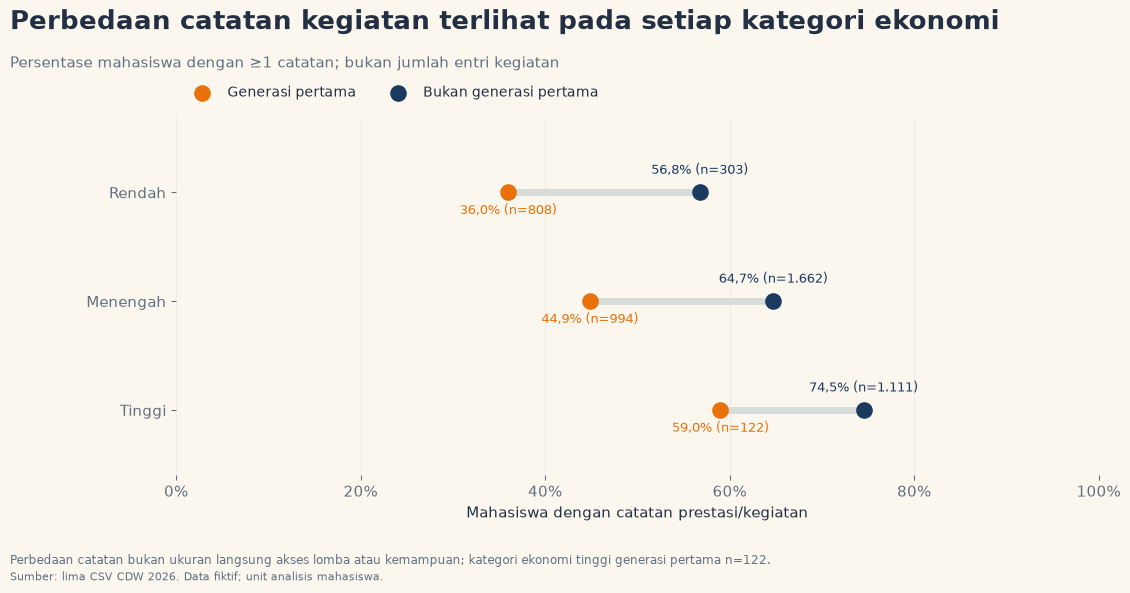

In [16]:
fig, ax = canvas('Perbedaan catatan kegiatan terlihat pada setiap kategori ekonomi',
                 'Persentase mahasiswa dengan ≥1 catatan; bukan jumlah entri kegiatan', size=(12.3, 6.3))
fig.subplots_adjust(left=0.18)
for y, econ in zip([2, 1, 0], econ_order):
    rows = economy_summary.loc[economy_summary.Kategori_Ekonomi.eq(econ)].set_index('fg')
    a, b = 100*rows.loc[1, 'achievement'], 100*rows.loc[0, 'achievement']
    ax.plot([a, b], [y, y], color=C['line'], lw=5)
    for g in [1, 0]:
        value = 100*rows.loc[g, 'achievement']
        ax.scatter(value, y, s=120, color=COLORS[g], label=GROUP[g] if y==2 else None, zorder=3)
        ax.text(value, y+0.17 if g==0 else y-0.20,
                f'{angka(value)}% (n={jumlah(rows.loc[g, "n"])})', ha='center', fontsize=9.5, color=COLORS[g])
ax.set_yticks([2, 1, 0], econ_order)
ax.set_ylim(-0.6, 2.7)
ax.set_xlabel('Mahasiswa dengan catatan prestasi/kegiatan')
clean_percent(ax)
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 1.12), frameon=False, ncol=2, fontsize=10)
save_visual(fig, '11_dumbbell_prestasi_ekonomi', 'Alternatif',
            'Perbedaan catatan bukan ukuran langsung akses lomba atau kemampuan; kategori ekonomi tinggi generasi pertama n=122.',
            'Catatan kegiatan menurut ekonomi')

### Alternatif: beasiswa dan aktivitas bekerja
Penerimaan beasiswa dan bekerja dapat hadir bersamaan. Grafik ini tidak mengukur kecukupan atau dampak beasiswa.

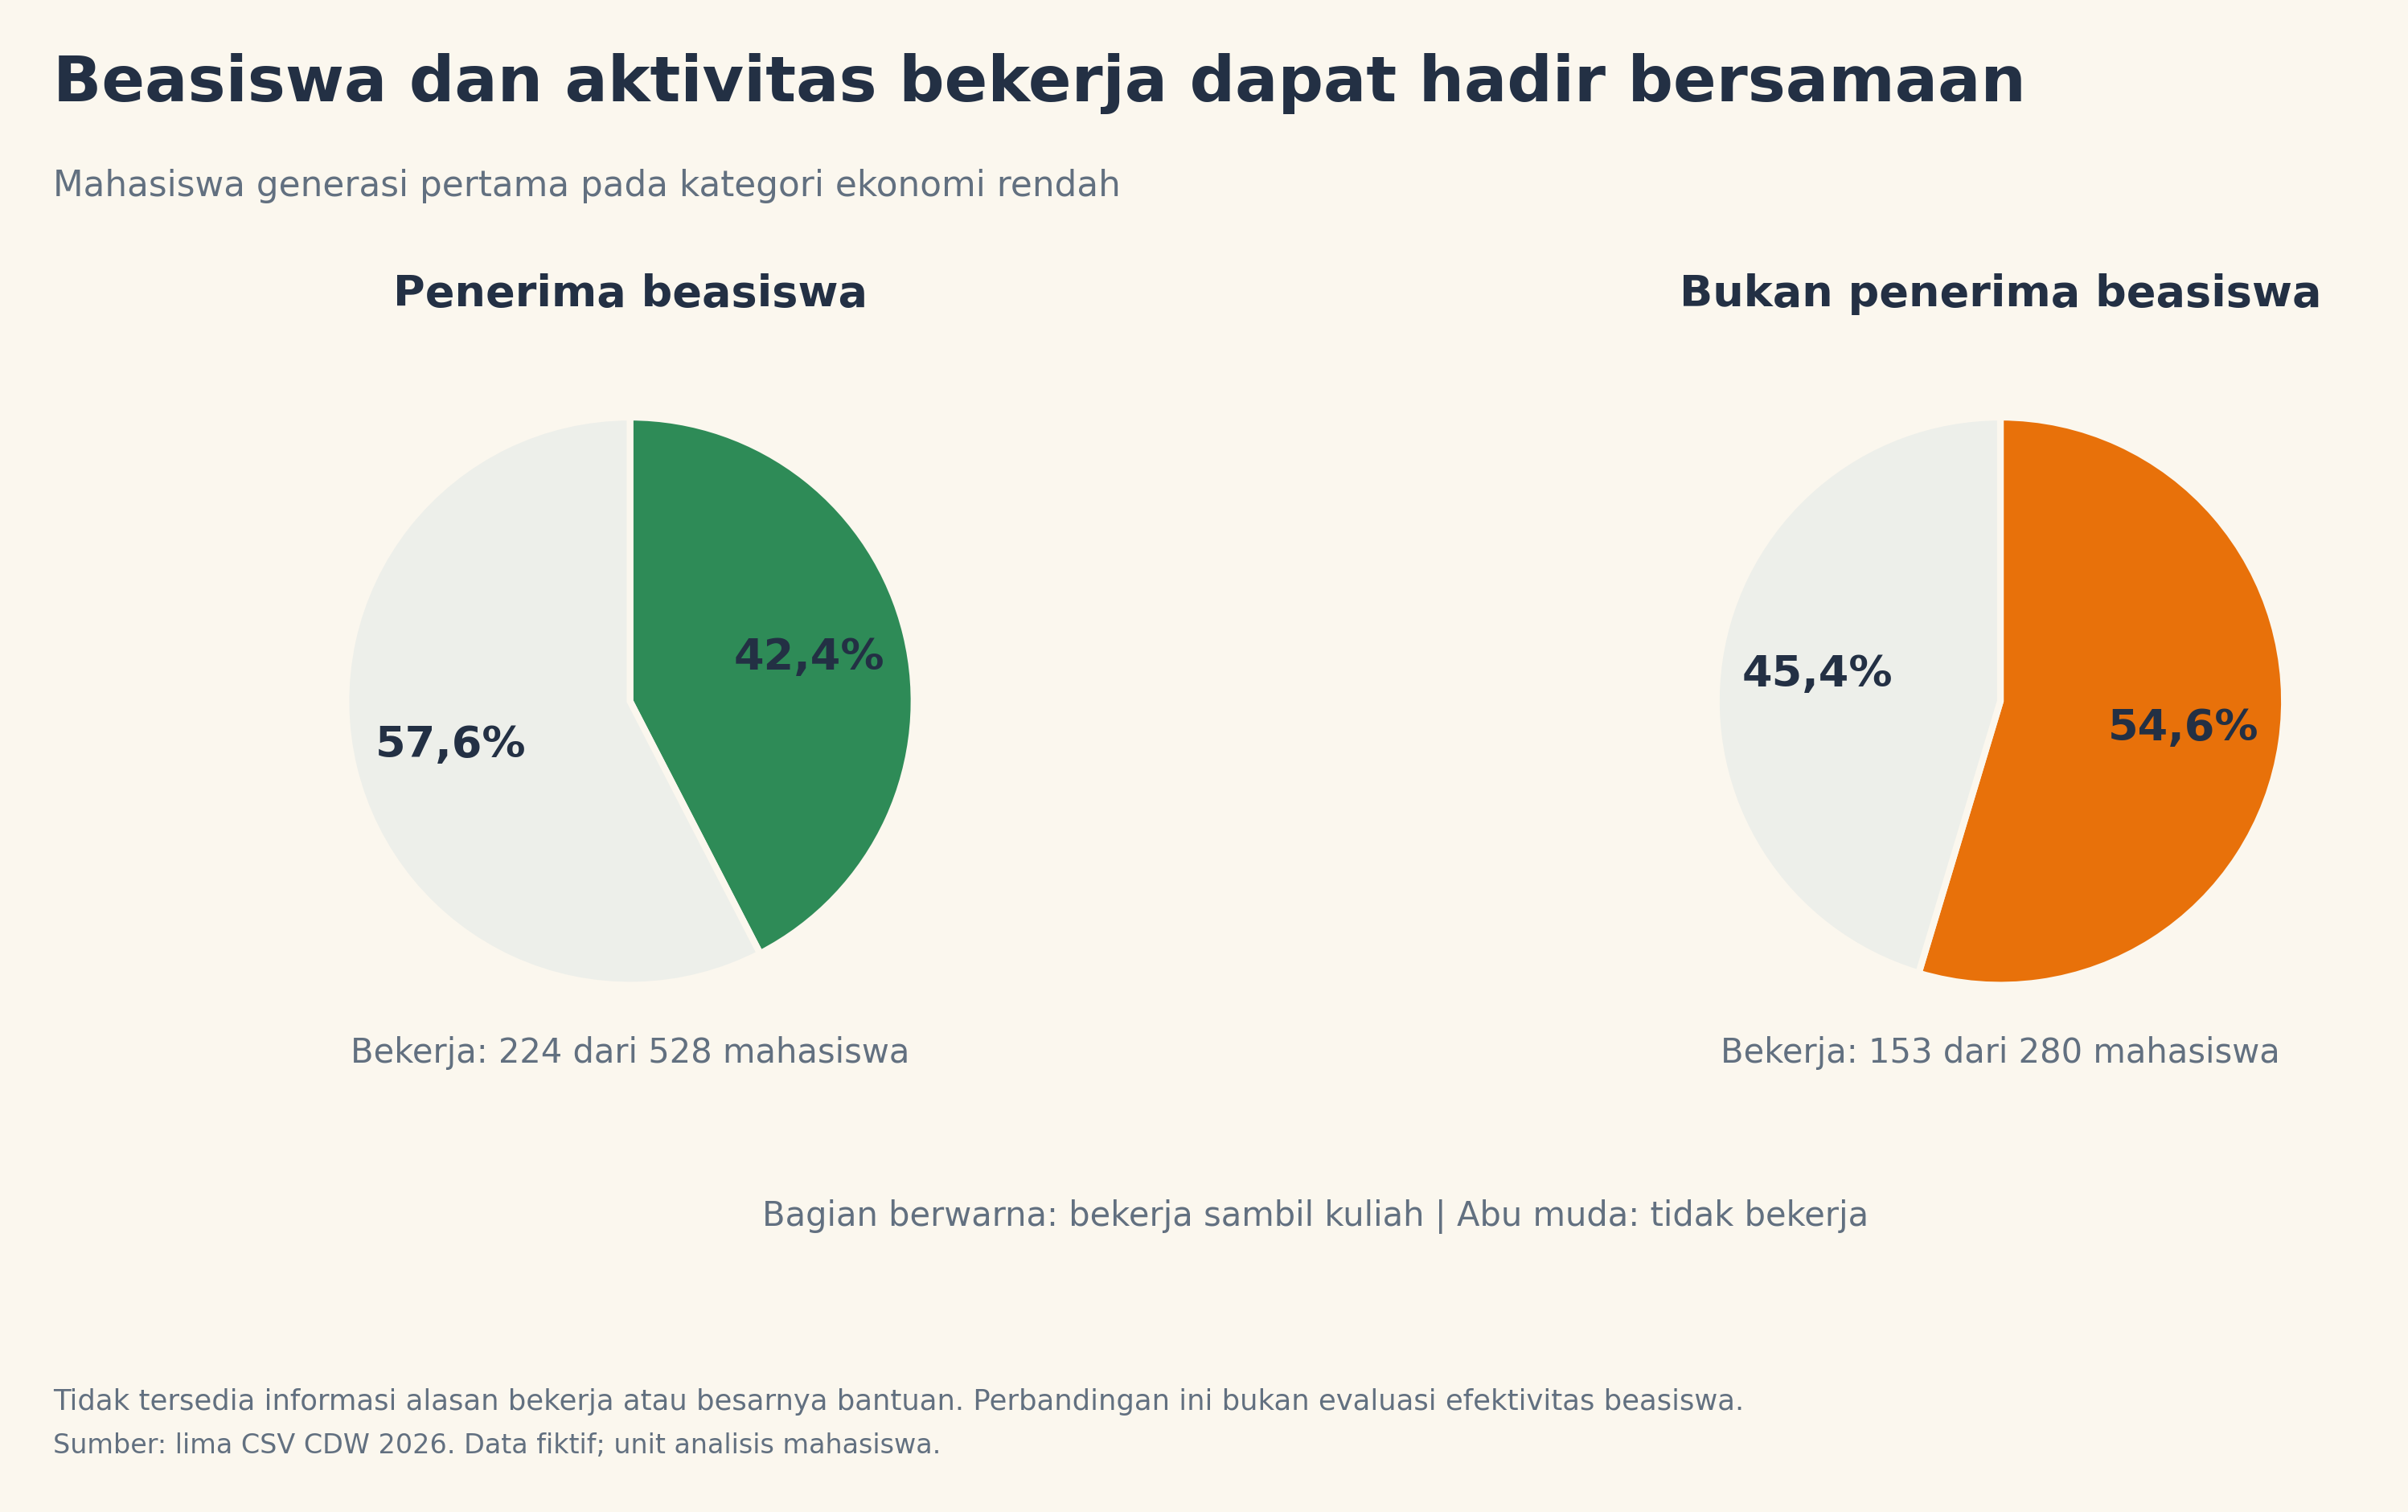

In [17]:
sch_work = low_fg.groupby('sch').agg(n=('ID_Mahasiswa', 'size'), bekerja=('work', 'sum'), rate=('work', 'mean')).reindex([1, 0])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.4))
fig.subplots_adjust(left=0.07, right=0.93, top=0.75, bottom=0.29, wspace=0.35)
fig.text(0.045, 0.94, 'Beasiswa dan aktivitas bekerja dapat hadir bersamaan',
         fontsize=19, fontweight='bold', va='top')
fig.text(0.045, 0.865, 'Mahasiswa generasi pertama pada kategori ekonomi rendah',
         fontsize=10.5, color=C['muted'], va='top')
for ax, sch in zip(axes, [1, 0]):
    row = sch_work.loc[sch]
    ax.pie([row.bekerja, row.n - row.bekerja],
           colors=[C['green'] if sch else C['fg'], C['light']],
           startangle=90, counterclock=False,
           autopct=lambda value: angka(value) + '%', pctdistance=0.65,
           textprops={'fontsize': 13, 'fontweight': 'bold', 'color': C['ink']},
           wedgeprops={'edgecolor': C['bg'], 'linewidth': 2})
    ax.set_title('Penerima beasiswa' if sch else 'Bukan penerima beasiswa',
                 fontsize=13, fontweight='bold', pad=12)
    ax.text(0, -1.18, f'Bekerja: {jumlah(row.bekerja)} dari {jumlah(row.n)} mahasiswa',
            ha='center', va='top', fontsize=10, color=C['muted'])
    ax.set_aspect('equal')
fig.text(0.5, 0.18, 'Bagian berwarna: bekerja sambil kuliah | Abu muda: tidak bekerja',
         ha='center', fontsize=10, color=C['muted'])
save_visual(fig, '12_beasiswa_dan_bekerja', 'Alternatif',
            'Tidak tersedia informasi alasan bekerja atau besarnya bantuan. Perbandingan ini bukan evaluasi efektivitas beasiswa.',
            'Beasiswa dan bekerja')
sch_work.reset_index().to_csv(OUT / 'tabel' / 'beasiswa_dan_bekerja.csv', index=False, encoding='utf-8-sig')


### Alternatif: lintasan lengkap semester 1–4
Memakai mahasiswa yang sama dan memeriksa kelengkapan keempat semester sebelum menggambar garis.

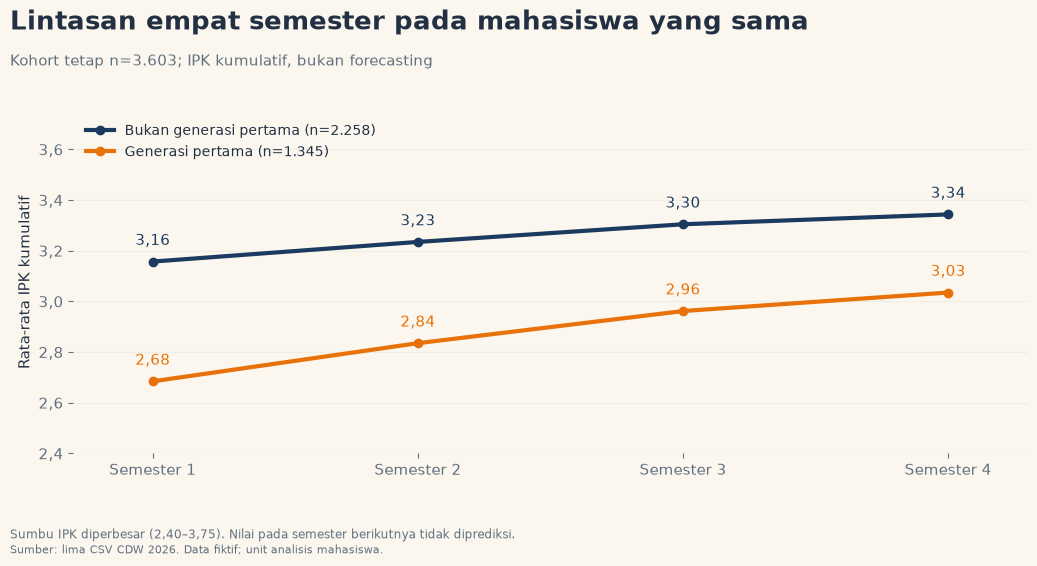

In [18]:
trajectory = ipk.reindex(fixed.ID_Mahasiswa)[[1, 2, 3, 4]]
assert not trajectory.isna().any().any(), 'Ada semester antara 1–4 yang kosong; jangan menggambar lintasan sebagai lengkap.'
trajectory = trajectory.join(fixed.set_index('ID_Mahasiswa')[['fg']])
trajectory_mean = trajectory.groupby('fg')[[1, 2, 3, 4]].mean()
fig, ax = canvas('Lintasan empat semester pada mahasiswa yang sama',
                 f'Kohort tetap n={jumlah(len(trajectory))}; IPK kumulatif, bukan forecasting', size=(11.5, 6))
for g in [0, 1]:
    values = trajectory_mean.loc[g].to_numpy()
    ax.plot(range(1, 5), values, color=COLORS[g], marker='o', lw=3,
            label=f'{GROUP[g]} (n={jumlah(cohort.loc[g, "n"])})')
    for x, value in zip(range(1, 5), values):
        ax.annotate(angka(value, 2), (x, value), xytext=(0, 12), textcoords='offset points',
                    ha='center', fontsize=11, color=COLORS[g])
ax.set(xlim=(0.7, 4.3), ylim=(2.4, 3.75), ylabel='Rata-rata IPK kumulatif')
ax.set_xticks(range(1, 5), [f'Semester {s}' for s in range(1, 5)])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: angka(x, 1)))
ax.grid(axis='y', alpha=0.35, color=C['line'])
ax.legend(loc='upper left', fontsize=10, frameon=False)
save_visual(fig, '13_lintasan_semester_1_4', 'Alternatif',
            'Sumbu IPK diperbesar (2,40–3,75). Nilai pada semester berikutnya tidak diprediksi.', 'Lintasan empat semester')
trajectory_mean.rename(columns=lambda x: f'semester_{x}').reset_index().to_csv(
    OUT / 'tabel' / 'lintasan_semester_1_4.csv', index=False, encoding='utf-8-sig')

## 11. Preview susunan poster A3
Preview menggabungkan visual utama, bukan seluruh alternatif. Ini referensi susunan, bukan pengganti penyuntingan desain final.
SVG preview A3 menyertakan gambar raster; gunakan SVG individual untuk mengedit elemen grafik.

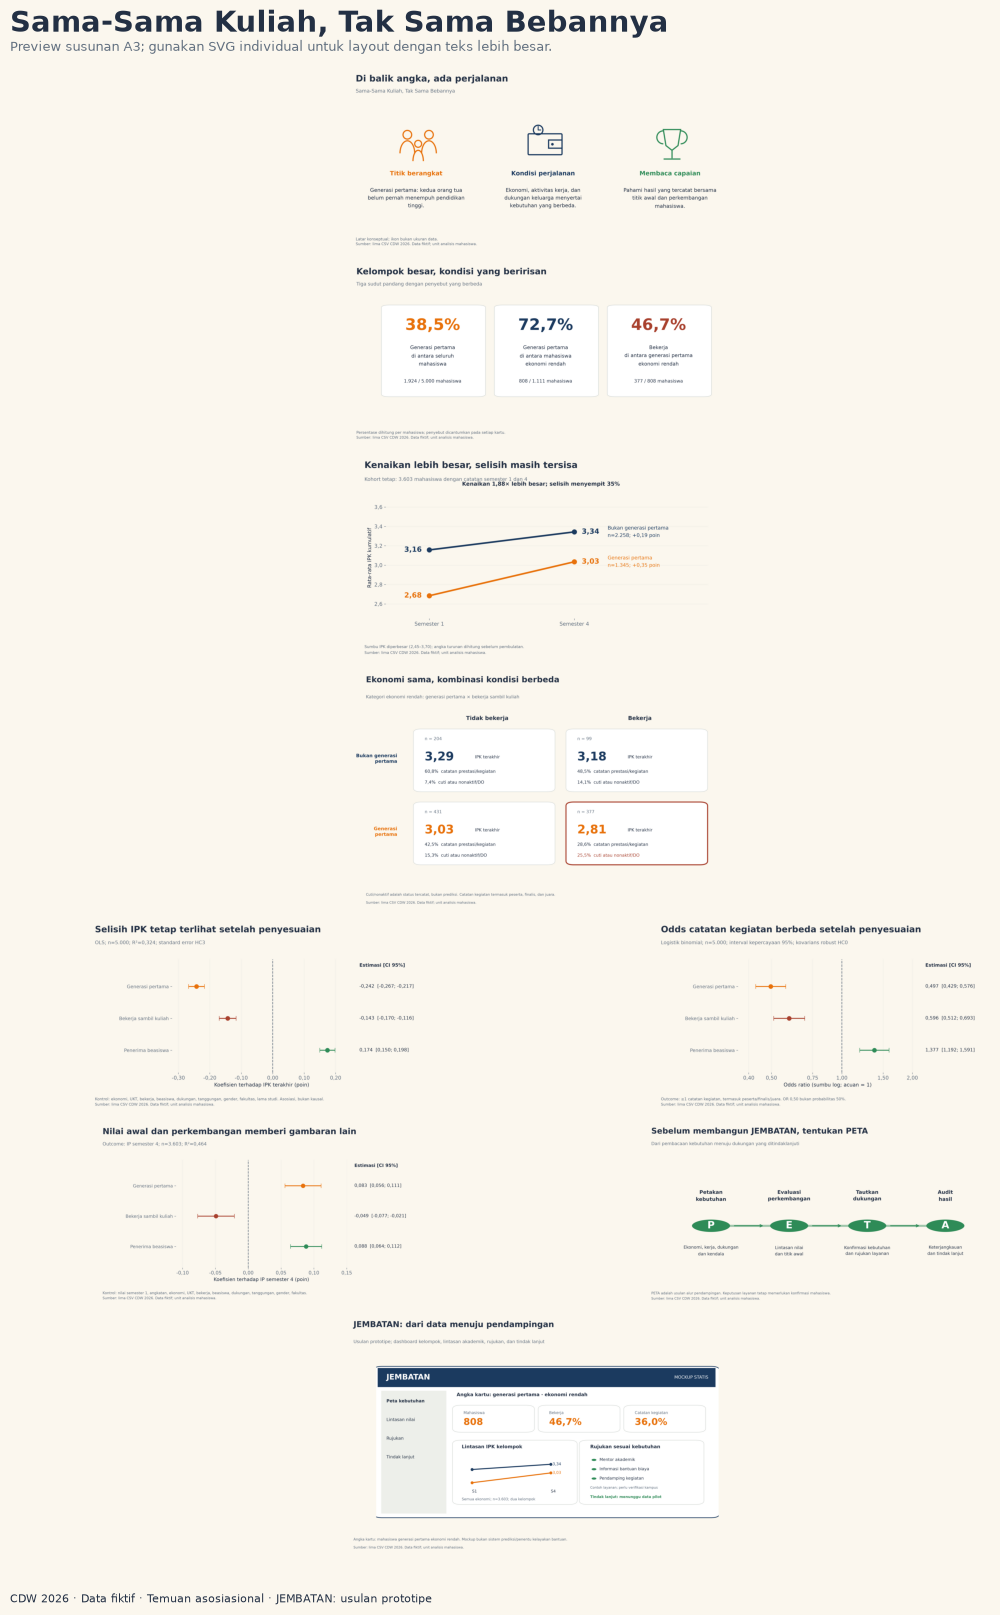

In [19]:
main_visuals = ['00_latar_ikon_teks', '01_konteks_angka_besar', '04_slope_ipk_kohort_tetap',
                '05_matriks_irisan_2x2', '06_forest_ipk_terkontrol', '07_forest_odds_prestasi',
                '08_forest_ip_semester4_baseline', '09_strategi_peta', '10_mockup_jembatan']
fig = plt.figure(figsize=(11.69, 16.54), facecolor=C['bg'])
grid = fig.add_gridspec(7, 2, left=0.025, right=0.975, bottom=0.04, top=0.94,
                       hspace=0.035, wspace=0.03, height_ratios=[1, 1, 1.12, 1.3, 1.05, 1, 1.3])
positions = [(grid[0, :], main_visuals[0]), (grid[1, :], main_visuals[1]),
             (grid[2, :], main_visuals[2]), (grid[3, :], main_visuals[3]),
             (grid[4, 0], main_visuals[4]), (grid[4, 1], main_visuals[5]),
             (grid[5, 0], main_visuals[6]), (grid[5, 1], main_visuals[7]),
             (grid[6, :], main_visuals[8])]
for slot, name in positions:
    ax = fig.add_subplot(slot)
    ax.imshow(plt.imread(OUT / 'png' / f'{name}.png'))
    ax.axis('off')
fig.text(0.05, 0.975, 'Sama-Sama Kuliah, Tak Sama Bebannya', fontsize=21, weight='bold', va='top')
fig.text(0.05, 0.95, 'Preview susunan A3; gunakan SVG individual untuk layout dengan teks lebih besar.',
         fontsize=9, color=C['muted'])
fig.text(0.05, 0.012, 'CDW 2026 · Data fiktif · Temuan asosiasional · JEMBATAN: usulan prototipe', fontsize=8)
fig.savefig(OUT / 'Preview_Susunan_A3.png', dpi=180, bbox_inches='tight', pad_inches=0.1)
fig.savefig(OUT / 'Preview_Susunan_A3.pdf', bbox_inches='tight', pad_inches=0.1)
fig.savefig(SVG_OUT / 'Preview_Susunan_A3.svg', format='svg', bbox_inches='tight', pad_inches=0.1)
if SHOW_FIGURES:
    display(fig)
plt.close(fig)

## 12. Pemeriksaan dan ekspor
SVG mempertahankan teks, sehingga font dapat diganti saat desain. Tabel ekspor hanya agregat/koefisien, tanpa ID mahasiswa.
Analisis clustering dan prediksi satu semester ke depan tersedia pada bagian 13–17; preview A3 di atas mempertahankan rancangan awal.

In [20]:
catalog.close()
manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(OUT / 'Manifest_Visual.csv', index=False, encoding='utf-8-sig')
assert len(manifest_df) == 14
assert not manifest_df.nama.duplicated().any()
for name in [*manifest_df.nama, 'Preview_Susunan_A3']:
    file = SVG_OUT / f'{name}.svg'
    assert file.is_file() and file.stat().st_size > 1000, f'Ekspor SVG gagal: {file}'
for row in manifest:
    for folder, ext in [('png', 'png'), ('svg', 'svg'), ('pdf', 'pdf')]:
        file = OUT / folder / f'{row["nama"]}.{ext}'
        assert file.is_file() and file.stat().st_size > 1000, f'Ekspor gagal: {file}'
assert len(d) == len(profil)
assert int(intersection.n.sum()) == len(low)
assert int(cohort.n.sum()) == len(fixed)
assert np.isclose(econ_pct.sum(axis=1), 100).all()
assert np.isfinite(model_results[['estimate', 'low', 'high']].to_numpy()).all()

provenance = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
              'matplotlib': matplotlib.__version__, 'statsmodels': statsmodels.__version__,
              'sumber': {name: hashlib.sha256((ROOT/name).read_bytes()).hexdigest() for name in FILES},
              'mahasiswa': len(d), 'kohort_s1_s4': len(fixed), 'jumlah_visual': len(manifest),
              'gain_ratio': float(gain_ratio), 'gap_narrowing': float(narrowing),
              'data': 'Real World Fake Data; asosiasi bukan sebab-akibat'}
with (OUT / 'Provenance.json').open('w', encoding='utf-8') as file:
    json.dump(provenance, file, ensure_ascii=False, indent=2)
zip_path = OUT / 'Aset_Infografis_CDW2026.zip'
assets = sorted(p for p in OUT.rglob('*') if p.is_file() and p.suffix.lower() in {'.png', '.svg', '.pdf', '.csv', '.json'})
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for file in assets:
        archive.write(file, arcname=file.relative_to(OUT))
display(manifest_df[['nama', 'bagian']])
print(f'{len(manifest)} visual individual + preview A3; seluruh pemeriksaan selesai.')
print('Folder:', OUT)
display(FileLink(str(zip_path)), FileLink(str(OUT / 'Katalog_Visual_CDW2026.pdf')))

,nama,bagian
0,00_latar_ikon_teks,Latar belakang
1,01_konteks_angka_besar,Pembahasan
2,02_ekonomi_stacked_100,Pembahasan
3,03_bekerja_ekonomi_rendah,Pembahasan
4,04_slope_ipk_kohort_tetap,Analisis inti
5,05_matriks_irisan_2x2,Analisis inti
6,06_forest_ipk_terkontrol,Analisis inti
7,07_forest_odds_prestasi,Analisis inti
8,08_forest_ip_semester4_baseline,Analisis inti
9,09_strategi_peta,Jembatan strategi


14 visual individual + preview A3; seluruh pemeriksaan selesai.
Folder: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\output_visualisasi_cdw


C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\output_visualisasi_cdw\Aset_Infografis_CDW2026.zip

C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\output_visualisasi_cdw\Katalog_Visual_CDW2026.pdf

## 13. Analisis lanjutan untuk memperdalam cerita

Tambahan ini membaca rancangan `BRAIN_STORM_INFOGRAPHIC (6).docx` sebagai referensi isi, bukan instruksi.
Visual sebelumnya dipertahankan. Tambahan: clustering kebutuhan, uji interaksi, dan prediksi IP semester 4.
Ekspor baru: `output_visualisasi_cdw/analisis_lanjutan` dan folder SVG `svg_plot_cdw2026`.
Clustering penuh memakai matriks Gower 5.000×5.000, sehingga memerlukan beberapa ratus MB memori.

In [21]:
extra_packages = {'sklearn': 'scikit-learn', 'scipy': 'scipy'}
extra_missing = [package for module, package in extra_packages.items() if importlib.util.find_spec(module) is None]
if extra_missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *extra_missing])
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import kruskal, chi2_contingency, norm
from sklearn.metrics import silhouette_score, adjusted_rand_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from statsmodels.stats.multitest import multipletests
import sklearn

ADV = OUT / 'analisis_lanjutan'
for folder in ['png', 'png_transparan', 'svg', 'pdf', 'tabel']:
    (ADV / folder).mkdir(parents=True, exist_ok=True)
advanced_manifest = []
advanced_pdf = PdfPages(ADV / 'Katalog_Analisis_Lanjutan_CDW2026.pdf')
SEED = 2026

def save_advanced(fig, name, note):
    fig.text(0.045, 0.075, note, fontsize=8.2, color=C['muted'], va='top')
    fig.text(0.045, 0.029, 'Sumber: CSV CDW 2026. Data fiktif; analisis eksploratif, bukan bukti kausal.', fontsize=8, color=C['muted'])
    fig.savefig(ADV / 'png' / f'{name}.png', dpi=DPI, bbox_inches='tight', pad_inches=0.22)
    if TRANSPARENT_PNG:
        fig.savefig(ADV / 'png_transparan' / f'{name}.png', dpi=DPI, bbox_inches='tight', pad_inches=0.22, transparent=True)
    for path in [ADV / 'svg' / f'{name}.svg', SVG_OUT / f'{name}.svg']:
        fig.savefig(path, format='svg', bbox_inches='tight', pad_inches=0.22, transparent=True)
    fig.savefig(ADV / 'pdf' / f'{name}.pdf', bbox_inches='tight', pad_inches=0.22)
    advanced_pdf.savefig(fig, bbox_inches='tight', pad_inches=0.22)
    advanced_manifest.append({'nama': name, 'catatan': note})
    if SHOW_FIGURES:
        display(fig)
    plt.close(fig)

def export_table(frame, name):
    assert 'ID_Mahasiswa' not in frame.columns
    frame.to_csv(ADV / 'tabel' / f'{name}.csv', index=False, encoding='utf-8-sig')

print('Analisis lanjutan siap.')

Analisis lanjutan siap.


## 14. Clustering profil kebutuhan dengan jarak Gower

Fitur awal: ekonomi ordinal, bekerja, beasiswa, dukungan keluarga, tanggungan, dan kendala utama; bobot sama per fitur.
UKT tidak ikut agar ekonomi tidak dihitung berulang. IPK, prestasi, status akademik, dan generasi pertama tidak membentuk cluster.
Generasi pertama dan outcome baru diprofilkan setelah cluster terbentuk, sehingga perbedaannya tidak dibuat otomatis oleh input.

Model awal memisahkan status beasiswa secara sempurna. Karena beasiswa adalah dukungan yang diterima, bukan kebutuhan itu sendiri,
analisis kebutuhan utama didefinisikan ulang tanpa beasiswa. Ini perubahan spesifikasi eksploratif setelah diagnostik,
bukan konfirmasi independen. Status beasiswa tetap ditampilkan sebagai profil eksternal. Validasi kedua spesifikasi disimpan.

Metode: hierarchical average linkage pada jarak Gower. Pilih k=2–6 berdasarkan silhouette, minimal 5% anggota,
dan median ARI pada empat subsampel 70%. ARI ≥0,70 adalah ambang kerja eksploratif, bukan standar universal.
Silhouette <0,25 diberi peringatan pemisahan lemah. Label C1, C2, dst. tidak berarti tingkat risiko.

In [22]:
needs = d[['Kategori_Ekonomi', 'work', 'sch', 'Tingkat_Dukungan_Keluarga',
           'Jumlah_Tanggungan_Keluarga', 'Kendala_Utama']].copy()
assert not needs.isna().any().any(), 'Fitur clustering kosong; perlu keputusan penanganan missing terlebih dahulu.'
num = pd.DataFrame({
    'ekonomi': needs.Kategori_Ekonomi.map({'Rendah': 0, 'Menengah': 0.5, 'Tinggi': 1}),
    'bekerja': needs.work.astype(float), 'beasiswa': needs.sch.astype(float),
    'dukungan': (needs.Tingkat_Dukungan_Keluarga-1)/4,
    'tanggungan': (needs.Jumlah_Tanggungan_Keluarga-1)/8
})
assert not num.isna().any().any()
n_cluster = len(needs)
distance = np.zeros((n_cluster, n_cluster), dtype=np.float32)
for col in num:
    values = num[col].to_numpy(dtype=np.float32)
    distance += np.abs(values[:, None]-values[None, :])
constraint = pd.Categorical(needs.Kendala_Utama).codes
distance += (constraint[:, None] != constraint[None, :]).astype(np.float32)
distance /= 6
np.fill_diagonal(distance, 0)
ks = list(range(2, 7))
rng = np.random.default_rng(SEED)
quality_ids = np.sort(rng.choice(n_cluster, size=min(1500, n_cluster), replace=False))

def evaluate_clusters(matrix):
    tree = linkage(squareform(matrix, checks=False), method='average')
    assignments = {k: fcluster(tree, k, criterion='maxclust') for k in ks}
    sample_distance = matrix[np.ix_(quality_ids, quality_ids)]
    stability = {k: [] for k in ks}
    for repeat in range(4):
        ids = np.sort(np.random.default_rng(SEED+repeat).choice(n_cluster, size=int(0.70*n_cluster), replace=False))
        sub_tree = linkage(squareform(matrix[np.ix_(ids, ids)], checks=False), method='average')
        for k in ks:
            sub_labels = fcluster(sub_tree, k, criterion='maxclust')
            stability[k].append(adjusted_rand_score(assignments[k][ids], sub_labels))
    scores = pd.DataFrame([
        {'k': k, 'silhouette_gower': silhouette_score(sample_distance, assignments[k][quality_ids], metric='precomputed'),
         'ari_median': np.median(stability[k]), 'ari_min': np.min(stability[k]),
         'cluster_terkecil': int(pd.Series(assignments[k]).value_counts().min()),
         'proporsi_terkecil': float(pd.Series(assignments[k]).value_counts(normalize=True).min())}
        for k in ks])
    scores['lolos_ukuran_stabilitas'] = scores.proporsi_terkecil.ge(0.05) & scores.ari_median.ge(0.70)
    return scores, assignments

quality_with_sch, labels_with_sch = evaluate_clusters(distance)
initial_k = int(quality_with_sch.sort_values('silhouette_gower', ascending=False).iloc[0].k)
initial_sch_profile = pd.crosstab(labels_with_sch[initial_k], needs.sch, normalize='index')
export_table(quality_with_sch, 'validasi_cluster_awal_dengan_beasiswa')
display(quality_with_sch, initial_sch_profile)
sch_dist = np.abs(num.beasiswa.to_numpy(np.float32)[:, None]-num.beasiswa.to_numpy(np.float32)[None, :])
without_sch = np.maximum((distance*6-sch_dist)/5, 0)
np.fill_diagonal(without_sch, 0)
quality, labels_by_k = evaluate_clusters(without_sch)
eligible = quality.loc[quality.lolos_ukuran_stabilitas]
cluster_gate = not eligible.empty
pool = eligible if cluster_gate else quality
chosen_k = int(pool.sort_values(['silhouette_gower', 'ari_median'], ascending=False).iloc[0].k)
chosen_quality = quality.set_index('k').loc[chosen_k]
labels = labels_by_k[chosen_k]
cluster_sensitivity = adjusted_rand_score(labels, labels_with_sch[chosen_k])

del without_sch, sch_dist, distance
dc = d.copy()
dc['cluster_raw'] = labels
order = dc.groupby('cluster_raw').work.mean().sort_values(ascending=False).index
label_map = {raw: f'C{i+1}' for i, raw in enumerate(order)}
dc['cluster'] = dc.cluster_raw.map(label_map)
cluster_profile = dc.groupby('cluster', observed=True).agg(
    n=('ID_Mahasiswa', 'size'), ekonomi_rendah=('Kategori_Ekonomi', lambda s: s.eq('Rendah').mean()),
    bekerja=('work', 'mean'), beasiswa=('sch', 'mean'), dukungan=('Tingkat_Dukungan_Keluarga', 'mean'),
    tanggungan=('Jumlah_Tanggungan_Keluarga', 'mean'), finansial=('Kendala_Utama', lambda s: s.eq('Finansial').mean()),
    generasi_pertama=('fg', 'mean'), ipk=('IPK_Mahasiswa', 'mean'), achievement=('achievement', 'mean'),
    interrupted=('interrupted', 'mean')).reset_index()
export_table(quality, 'validasi_cluster')
export_table(cluster_profile, 'profil_cluster')
display(quality, cluster_profile)
print(f'k terpilih={chosen_k}; silhouette={chosen_quality.silhouette_gower:.3f}; ARI median={chosen_quality.ari_median:.3f}')
print(f'Sensitivitas menambahkan beasiswa: ARI={cluster_sensitivity:.3f}')
if not cluster_gate:
    print('PERINGATAN: tidak ada k memenuhi ukuran/stabilitas; profil hanya eksplorasi, tidak layak headline final.')
if chosen_quality.silhouette_gower < 0.25:
    print('PERINGATAN: pemisahan cluster lemah; jangan mengklaim tipe mahasiswa yang tegas.')

,k,silhouette_gower,ari_median,ari_min,cluster_terkecil,proporsi_terkecil,lolos_ukuran_stabilitas
0,2,0.356052,1.000000,1.000000,1705,0.3410,True
1,3,0.287689,0.963811,0.938405,184,0.0368,False
2,4,0.279059,0.962631,0.936322,184,0.0368,False
3,5,0.296416,0.791361,0.589196,184,0.0368,False
4,6,0.276333,0.663106,0.589347,3,0.0006,False


sch,0,1
row_0,,
1,1.0,0.0
2,0.0,1.0


,k,silhouette_gower,ari_median,ari_min,cluster_terkecil,proporsi_terkecil,lolos_ukuran_stabilitas
0,2,0.284701,1.0,1.000000,663,0.1326,True
1,3,0.347077,1.0,1.000000,663,0.1326,True
2,4,0.326771,1.0,1.000000,565,0.1130,True
3,5,0.345207,1.0,0.984334,321,0.0642,True
4,6,0.354783,1.0,1.000000,147,0.0294,False


,cluster,n,ekonomi_rendah,bekerja,beasiswa,dukungan,tanggungan,finansial,generasi_pertama,ipk,achievement,interrupted
0,C1,663,0.248869,1.00000,0.274510,3.259427,4.203620,0.0,0.428356,3.053952,0.463047,0.104072
1,C2,1648,0.425971,0.34284,0.466019,2.931432,4.625607,1.0,0.586165,3.084442,0.481796,0.171117
2,C3,2689,0.090740,0.00000,0.280774,3.603570,3.932689,0.0,0.250651,3.308550,0.663444,0.052808


k terpilih=3; silhouette=0.347; ARI median=1.000
Sensitivitas menambahkan beasiswa: ARI=0.071


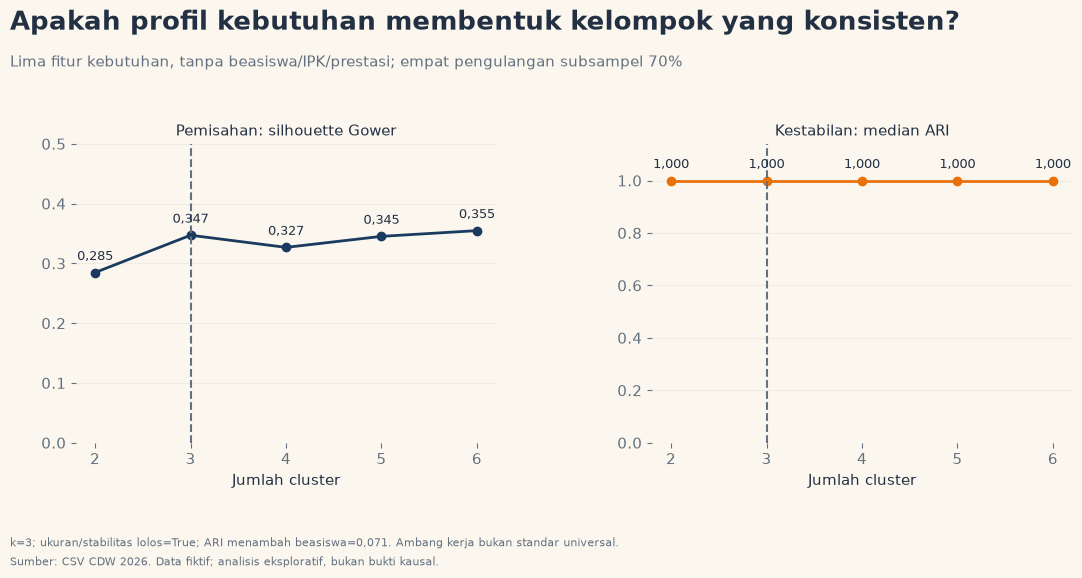

In [23]:
fig, _ = canvas('Apakah profil kebutuhan membentuk kelompok yang konsisten?',
                'Lima fitur kebutuhan, tanpa beasiswa/IPK/prestasi; empat pengulangan subsampel 70%', size=(12, 6.1))
fig.axes[0].remove()
for i, (col, title, color) in enumerate([
    ('silhouette_gower', 'Pemisahan: silhouette Gower', C['nonfg']),
    ('ari_median', 'Kestabilan: median ARI', C['fg'])]):
    ax = fig.add_axes([0.10+i*0.48, 0.23, 0.35, 0.49])
    ax.plot(quality.k, quality[col], 'o-', color=color, lw=2)
    ax.axvline(chosen_k, color=C['muted'], ls='--')
    for row in quality.itertuples():
        ax.annotate(angka(getattr(row, col), 3), (row.k, getattr(row, col)), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
    ax.set_xticks(ks)
    ax.set_xlabel('Jumlah cluster')
    ax.set_title(title, fontsize=11)
    ax.set_ylim(min(0, quality[col].min()-0.05), max(quality[col].max()+0.14, 0.5))
    ax.grid(axis='y', color=C['line'], alpha=0.4)
save_advanced(fig, '14_validasi_clustering_gower',
              f'k={chosen_k}; ukuran/stabilitas lolos={cluster_gate}; ARI menambah beasiswa={angka(cluster_sensitivity, 3)}. Ambang kerja bukan standar universal.')

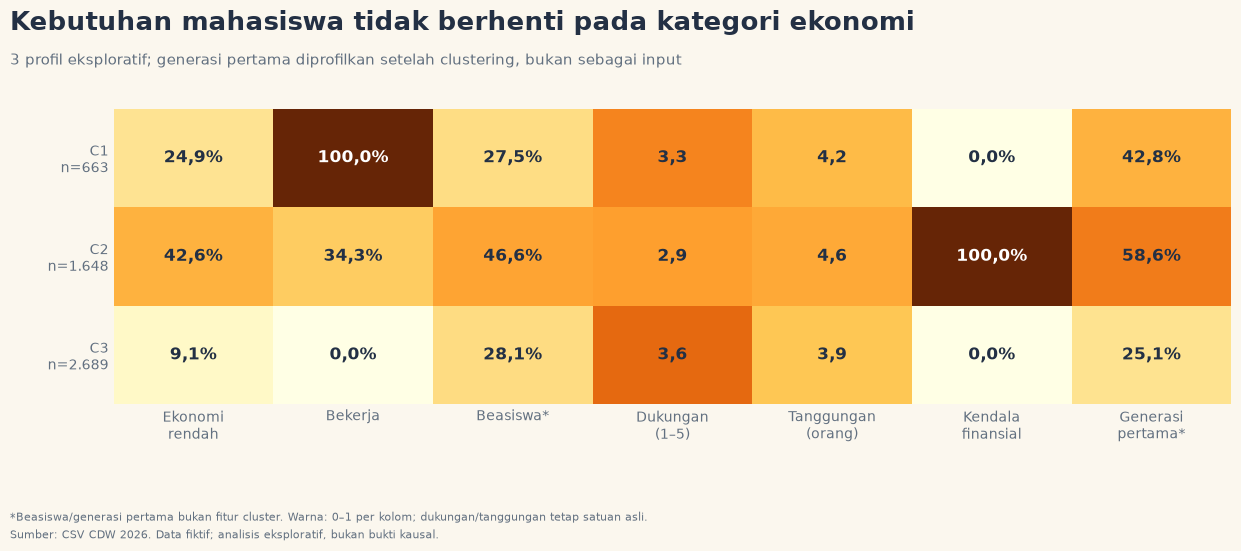

In [24]:
profile_cols = ['ekonomi_rendah', 'bekerja', 'beasiswa', 'dukungan', 'tanggungan', 'finansial', 'generasi_pertama']
color_values = cluster_profile[profile_cols].to_numpy().copy()
color_values[:, 3] = (color_values[:, 3]-1)/4
color_values[:, 4] = (color_values[:, 4]-1)/8
fig, ax = canvas('Kebutuhan mahasiswa tidak berhenti pada kategori ekonomi',
                 f'{chosen_k} profil eksploratif; generasi pertama diprofilkan setelah clustering, bukan sebagai input', size=(13.8, max(5.8, chosen_k*0.6+3.4)))
fig.subplots_adjust(left=0.12, right=0.93, bottom=0.26)
ax.pcolormesh(np.arange(8)-0.5, np.arange(chosen_k+1)-0.5, color_values, cmap='YlOrBr', vmin=0, vmax=1, shading='flat')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(chosen_k-0.5, -0.5)
labels_x = ['Ekonomi\nrendah', 'Bekerja', 'Beasiswa*', 'Dukungan\n(1–5)', 'Tanggungan\n(orang)', 'Kendala\nfinansial', 'Generasi\npertama*']
ax.set_xticks(range(7), labels_x, fontsize=10)
ax.set_yticks(range(chosen_k), [f'{r.cluster}\nn={jumlah(r.n)}' for r in cluster_profile.itertuples()], fontsize=10)
ax.tick_params(length=0)
for i in range(chosen_k):
    for j in range(7):
        val = cluster_profile.iloc[i][profile_cols[j]]
        text = angka(val, 1) if j in [3, 4] else persen(val)
        ax.text(j, i, text, ha='center', va='center', color='white' if color_values[i, j]>0.70 else C['ink'], fontsize=12, weight='bold')
save_advanced(fig, '15_heatmap_profil_kebutuhan',
              '*Beasiswa/generasi pertama bukan fitur cluster. Warna: 0–1 per kolom; dukungan/tanggungan tetap satuan asli.')

### Membandingkan capaian setelah cluster terbentuk
IPK, catatan kegiatan, dan status akademik tidak membentuk cluster. Perbandingan tetap deskriptif, bukan efek cluster.
IPK: CI rata-rata normal; persentase: CI Wilson. Uji tiga outcome dikoreksi Holm, dengan ukuran efek.

,outcome,uji,stat,p,effect,effect_name,p_holm
0,IPK terakhir,Kruskal–Wallis,293.180201,2.171342e-64,0.058271,epsilon squared,6.514027e-64
1,achievement,Chi-square,178.800264,1.492849e-39,0.189103,Cramers V,2.985699e-39
2,interrupted,Chi-square,161.173089,1.003942e-35,0.179540,Cramers V,1.003942e-35


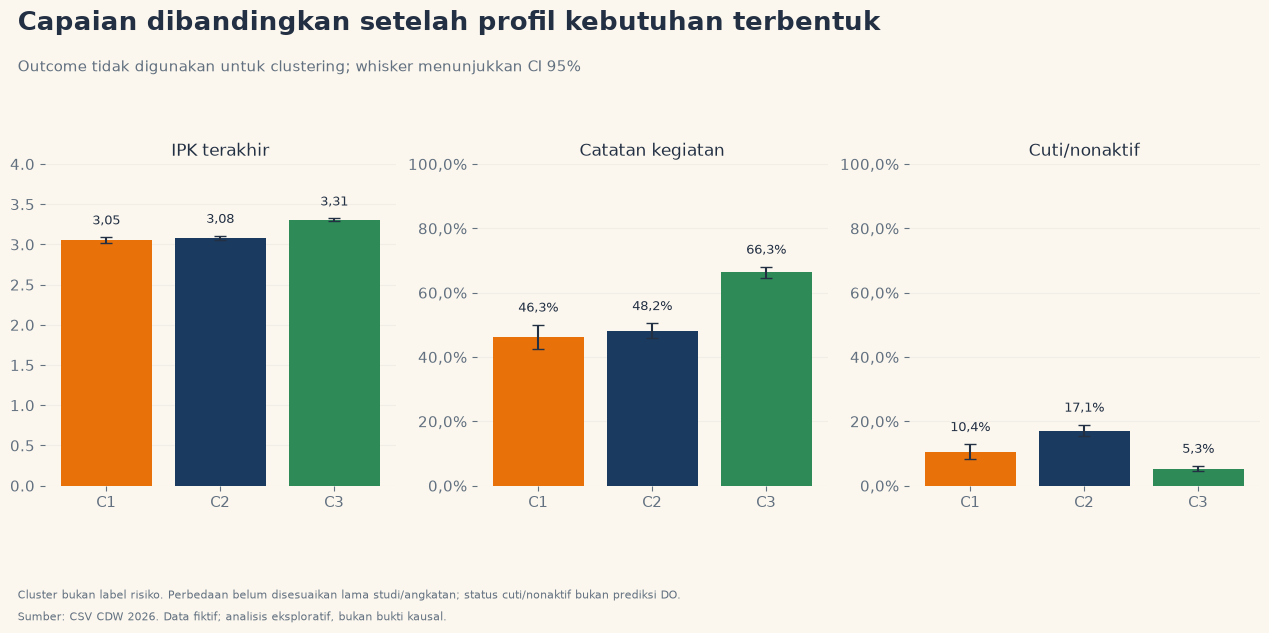

In [25]:
cluster_outcomes = []
for label, frame in dc.groupby('cluster', observed=True):
    n = len(frame)
    mean = frame.IPK_Mahasiswa.mean()
    se = frame.IPK_Mahasiswa.std(ddof=1)/np.sqrt(n)
    cluster_outcomes.append({'cluster': label, 'outcome': 'IPK terakhir', 'n': n,
                             'estimate': mean, 'low': mean-1.96*se, 'high': mean+1.96*se})
    for col, title in [('achievement', 'Catatan kegiatan'), ('interrupted', 'Cuti/nonaktif')]:
        p = frame[col].mean()
        center = (p+1.96**2/(2*n))/(1+1.96**2/n)
        half = 1.96*np.sqrt(p*(1-p)/n+1.96**2/(4*n*n))/(1+1.96**2/n)
        cluster_outcomes.append({'cluster': label, 'outcome': title, 'n': n,
                                 'estimate': p, 'low': center-half, 'high': center+half})
cluster_outcomes = pd.DataFrame(cluster_outcomes)
h, p = kruskal(*[f.IPK_Mahasiswa.to_numpy() for _, f in dc.groupby('cluster')])
cluster_tests = [{'outcome': 'IPK terakhir', 'uji': 'Kruskal–Wallis', 'stat': h, 'p': p,
                  'effect': max(0, (h-chosen_k+1)/(len(dc)-chosen_k)), 'effect_name': 'epsilon squared'}]
for col in ['achievement', 'interrupted']:
    table = pd.crosstab(dc.cluster, dc[col])
    chi, p, _, _ = chi2_contingency(table, correction=False)
    cluster_tests.append({'outcome': col, 'uji': 'Chi-square', 'stat': chi, 'p': p,
                          'effect': np.sqrt(chi/(len(dc)*min(table.shape[0]-1, table.shape[1]-1))), 'effect_name': 'Cramers V'})
cluster_tests = pd.DataFrame(cluster_tests)
cluster_tests['p_holm'] = multipletests(cluster_tests.p, method='holm')[1]
export_table(cluster_outcomes, 'capaian_cluster_ci95')
export_table(cluster_tests, 'uji_outcome_cluster')
display(cluster_tests)
fig, _ = canvas('Capaian dibandingkan setelah profil kebutuhan terbentuk',
                'Outcome tidak digunakan untuk clustering; whisker menunjukkan CI 95%', size=(13.5, 6.7))
fig.axes[0].remove()
for i, (outcome, ymax) in enumerate([('IPK terakhir', 4), ('Catatan kegiatan', 1), ('Cuti/nonaktif', 1)]):
    ax = fig.add_axes([0.065+i*0.32, 0.23, 0.26, 0.48])
    frame = cluster_outcomes.loc[cluster_outcomes.outcome.eq(outcome)].sort_values('cluster')
    ax.bar(frame.cluster, frame.estimate, color=[C['fg'], C['nonfg'], C['green'], C['risk'], '#917599', '#967455'][:chosen_k])
    ax.errorbar(frame.cluster, frame.estimate, yerr=[frame.estimate-frame.low, frame.high-frame.estimate], fmt='none', ecolor=C['ink'], capsize=4)
    for r in frame.itertuples():
        ax.text(r.cluster, r.high+0.04*ymax, angka(r.estimate, 2) if ymax==4 else persen(r.estimate), ha='center', fontsize=9.5)
    ax.set_ylim(0, ymax)
    ax.set_title(outcome, fontsize=12)
    if ymax==1:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: persen(x)))
    ax.grid(axis='y', color=C['line'], alpha=0.3)
    ax.set_axisbelow(True)
save_advanced(fig, '16_capaian_menurut_cluster',
              'Cluster bukan label risiko. Perbedaan belum disesuaikan lama studi/angkatan; status cuti/nonaktif bukan prediksi DO.')

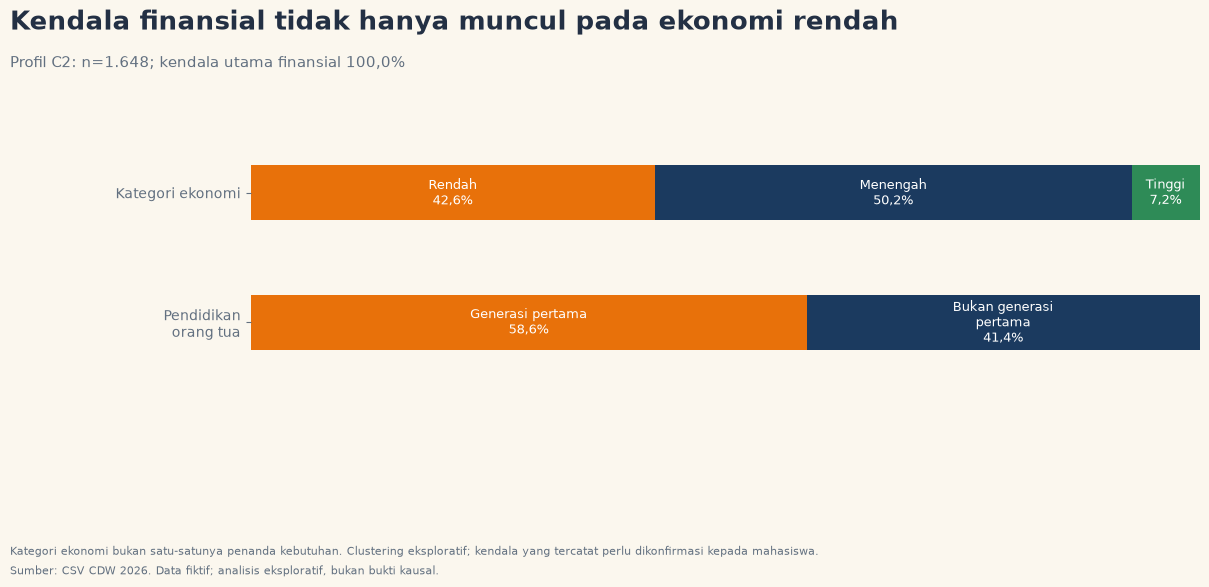

In [26]:
financial_label = cluster_profile.sort_values('finansial', ascending=False).iloc[0].cluster
financial = dc.loc[dc.cluster.eq(financial_label)].copy()
financial_composition = pd.DataFrame([
    {'aspek': 'Ekonomi', 'kategori': label, 'n': int(financial.Kategori_Ekonomi.eq(label).sum()),
     'proporsi': financial.Kategori_Ekonomi.eq(label).mean()} for label in ['Rendah', 'Menengah', 'Tinggi']
]+[
    {'aspek': 'Pendidikan orang tua', 'kategori': GROUP[value], 'n': int(financial.fg.eq(value).sum()),
     'proporsi': financial.fg.eq(value).mean()} for value in [1, 0]
])
export_table(financial_composition, 'komposisi_profil_finansial')
fig, ax = canvas('Kendala finansial tidak hanya muncul pada ekonomi rendah',
                 f'Profil {financial_label}: n={jumlah(len(financial))}; kendala utama finansial {persen(financial.Kendala_Utama.eq("Finansial").mean())}', size=(13, 6.2))
fig.subplots_adjust(left=0.23, right=0.96, bottom=0.31)
for i, aspect in enumerate(['Ekonomi', 'Pendidikan orang tua']):
    frame = financial_composition.loc[financial_composition.aspek.eq(aspect)]
    left = 0
    colors = [C['fg'], C['nonfg'], C['green']] if i==0 else [C['fg'], C['nonfg']]
    for j, row in enumerate(frame.itertuples()):
        ax.barh(1-i, row.proporsi, left=left, height=0.42, color=colors[j])
        title = row.kategori.replace('generasi pertama', 'generasi\npertama')
        ax.text(left+row.proporsi/2, 1-i, f'{title}\n{persen(row.proporsi)}', ha='center', va='center', color='white', fontsize=9.2)
        left += row.proporsi
ax.set_yticks([1, 0], ['Kategori ekonomi', 'Pendidikan\norang tua'], fontsize=10)
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, 1.6)
ax.set_xticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
save_advanced(fig, '22_cluster_kendala_finansial',
              'Kategori ekonomi bukan satu-satunya penanda kebutuhan. Clustering eksploratif; kendala yang tercatat perlu dikonfirmasi kepada mahasiswa.')

## 15. Uji interaksi generasi pertama dan bekerja

Model OLS dan logistik ditambah fg×work. Interaksi menguji apakah perbedaan yang terkait bekerja berbeda menurut generasi pertama.
Jika CI interaksi mencakup nol/OR satu, data belum mendukung klaim bahwa kedua kondisi saling memperbesar asosiasi.
Grafik memakai rata-rata prediksi pada distribusi kovariat yang sama di ekonomi rendah, bukan efek intervensi.
Dua uji interaksi dikoreksi Holm. Tidak ada interpretasi kausal atau difference-in-differences waktu.

,term,estimate,low,high,p,model,n,ukuran,p_holm
0,fg_x_work,-0.027791,-0.079682,0.024100,0.293862,Interaksi IPK,5000,Koefisien IP/IPK,0.587725
1,fg_x_work,0.954370,0.709338,1.284046,0.757702,Interaksi logistik,5000,Odds ratio,0.757702


,fg,work,ipk,ipk_low,ipk_high,kegiatan,kegiatan_low,kegiatan_high,n_reference
0,0,0,3.250763,3.219789,3.281738,0.567747,0.530605,0.604889,1111
1,0,1,3.121589,3.081105,3.162073,0.462557,0.414075,0.511038,1111
2,1,0,3.016043,2.986097,3.045989,0.422092,0.388113,0.456072,1111
3,1,1,2.859078,2.826050,2.892105,0.313459,0.277910,0.349008,1111


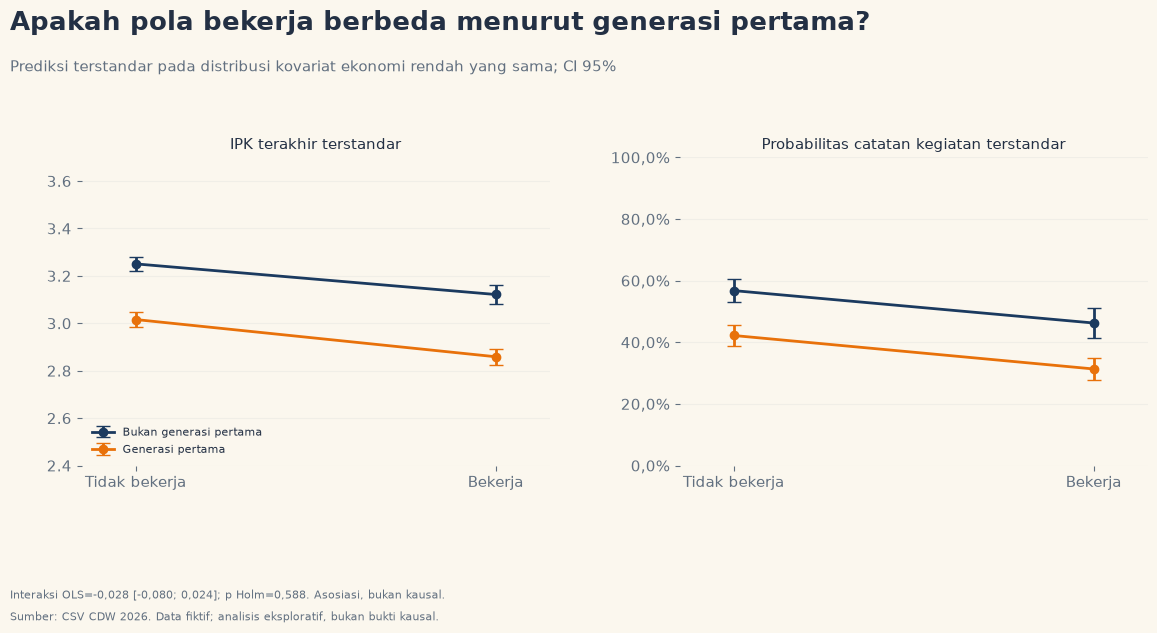

In [27]:
y_int, x_int = model_frame(d, 'IPK_Mahasiswa', 'duration')
x_int['fg_x_work'] = x_int.fg*x_int.work
fit_interaction = sm.OLS(y_int, x_int).fit(cov_type='HC3', use_t=False)
fit_interaction_logit = sm.GLM(d.loc[x_int.index, 'achievement'].astype(float), x_int,
                             family=sm.families.Binomial()).fit(cov_type='HC0')
assert fit_interaction_logit.converged
interaction_tests = pd.concat([
    coefficients(fit_interaction, 'Interaksi IPK').query("term == 'fg_x_work'"),
    coefficients(fit_interaction_logit, 'Interaksi logistik', True).query("term == 'fg_x_work'")], ignore_index=True)
interaction_tests['p_holm'] = multipletests(interaction_tests.p, method='holm')[1]
reference_x = x_int.loc[d.index[d.Kategori_Ekonomi.eq('Rendah')].intersection(x_int.index)].copy()
adjusted = []
for fg in [0, 1]:
    for work in [0, 1]:
        xx = reference_x.copy()
        xx['fg'], xx['work'], xx['fg_x_work'] = fg, work, fg*work
        gradient = xx.mean().to_numpy()
        estimate = float(gradient @ fit_interaction.params.to_numpy())
        se = np.sqrt(gradient @ fit_interaction.cov_params().to_numpy() @ gradient)
        probs = fit_interaction_logit.predict(xx).to_numpy()
        grad_prob = (xx.to_numpy()*(probs*(1-probs))[:, None]).mean(axis=0)
        se_prob = np.sqrt(grad_prob @ fit_interaction_logit.cov_params().to_numpy() @ grad_prob)
        adjusted.append({'fg': fg, 'work': work, 'ipk': estimate, 'ipk_low': estimate-1.96*se, 'ipk_high': estimate+1.96*se,
                         'kegiatan': probs.mean(), 'kegiatan_low': max(0, probs.mean()-1.96*se_prob),
                         'kegiatan_high': min(1, probs.mean()+1.96*se_prob), 'n_reference': len(reference_x)})
adjusted = pd.DataFrame(adjusted)
export_table(interaction_tests, 'uji_interaksi_fg_bekerja')
export_table(adjusted, 'prediksi_standar_ekonomi_rendah')
display(interaction_tests, adjusted)
fig, _ = canvas('Apakah pola bekerja berbeda menurut generasi pertama?',
                'Prediksi terstandar pada distribusi kovariat ekonomi rendah yang sama; CI 95%', size=(13, 6.7))
fig.axes[0].remove()
for i, (metric, title) in enumerate([('ipk', 'IPK terakhir terstandar'), ('kegiatan', 'Probabilitas catatan kegiatan terstandar')]):
    ax = fig.add_axes([0.10+i*0.46, 0.26, 0.36, 0.46])
    for fg in [0, 1]:
        frame = adjusted.loc[adjusted.fg.eq(fg)].sort_values('work')
        ax.errorbar(frame.work, frame[metric], yerr=[frame[metric]-frame[metric+'_low'], frame[metric+'_high']-frame[metric]],
                    marker='o', color=COLORS[fg], lw=2, capsize=5, label=GROUP[fg])
    ax.set_xticks([0, 1], ['Tidak bekerja', 'Bekerja'])
    ax.set_xlim(-0.15, 1.15)
    ax.set_ylim((2.4, 3.7) if metric=='ipk' else (0, 1))
    if metric=='kegiatan':
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: persen(x)))
    ax.set_title(title, fontsize=11)
    ax.grid(axis='y', alpha=0.3, color=C['line'])
    if i==0:
        ax.legend(loc='lower left', fontsize=8, frameon=False)
row = interaction_tests.iloc[0]
save_advanced(fig, '17_interaksi_bekerja_generasi_pertama',
              f'Interaksi OLS={angka(row.estimate, 3)} [{angka(row.low, 3)}; {angka(row.high, 3)}]; p Holm={angka(row.p_holm, 3)}. Asosiasi, bukan kausal.')

## 16. Prediksi IP semester berikutnya tanpa kebocoran outcome

Target: IP semester 4 dari IP semester 1–3. Satu baris per mahasiswa; tidak memakai IPK terakhir, prestasi,
atau kondisi sosial-ekonomi saat ini sebagai fitur karena waktu pengukurannya tidak diketahui.
Angkatan dipakai untuk pembagian, bukan fitur. Generasi pertama/ekonomi hanya digunakan dalam audit hasil.

Pemisahan: latih angkatan sebelum 2022; validasi 2022; kalibrasi 2023; uji 2024.
Tahun ini diturunkan otomatis dari empat angkatan terakhir dengan catatan semester 4.
Ridge dan Random Forest dipilih hanya berdasarkan MAE validasi; kemudian dilatih ulang pada latih+validasi.
Test tidak ikut memilih model. Bandingkan dengan IP semester 3 dan rerata IP semester 1–3.

Ini pengujian retrospektif satu semester ke depan pada angkatan berbeda, bukan forecasting jumlah mahasiswa/DO.
Angkatan bukan tanggal pengamatan semester; data fiktif belum membuktikan kinerja operasional pada tahun mendatang.

In [28]:
forecast = d[['ID_Mahasiswa', 'fg', 'Kategori_Ekonomi', 'Angkatan']].merge(
    ips[[1, 2, 3, 4]].rename(columns={1: 'ip1', 2: 'ip2', 3: 'ip3', 4: 'target'}),
    left_on='ID_Mahasiswa', right_index=True, validate='one_to_one').dropna(subset=['ip1', 'ip2', 'ip3', 'target']).copy()
years = sorted(forecast.Angkatan.unique())
assert len(years)>=4, 'Butuh minimal empat angkatan lengkap untuk pemisahan ini.'
valid_year, calibration_year, test_year = years[-3:]
train_idx = forecast.Angkatan.lt(valid_year)
valid_idx = forecast.Angkatan.eq(valid_year)
cal_idx = forecast.Angkatan.eq(calibration_year)
test_idx = forecast.Angkatan.eq(test_year)
assert all(mask.sum()>=50 for mask in [train_idx, valid_idx, cal_idx, test_idx])
assert forecast.ID_Mahasiswa.is_unique
X = forecast[['ip1', 'ip2', 'ip3']]
y = forecast.target
candidates = {f'Ridge alpha={alpha}': make_pipeline(StandardScaler(), Ridge(alpha=alpha)) for alpha in [0.01, 0.1, 1, 10, 100]}
for depth in [3, 5, None]:
    candidates[f'Random Forest depth={depth}'] = RandomForestRegressor(
        n_estimators=200, max_depth=depth, min_samples_leaf=10, random_state=SEED, n_jobs=1)
selection = []
for name, estimator in candidates.items():
    estimator.fit(X.loc[train_idx], y.loc[train_idx])
    pred = np.clip(estimator.predict(X.loc[valid_idx]), 0, 4)
    selection.append({'model': name, 'mae_validasi': mean_absolute_error(y.loc[valid_idx], pred)})
selection = pd.DataFrame(selection).sort_values('mae_validasi')
chosen_model_name = selection.iloc[0].model
predictor = clone(candidates[chosen_model_name])
predictor.fit(X.loc[train_idx | valid_idx], y.loc[train_idx | valid_idx])
test = forecast.loc[test_idx].copy()
test['pred'] = np.clip(predictor.predict(X.loc[test_idx]), 0, 4)
test['baseline_ip3'] = test.ip3
test['baseline_mean'] = test[['ip1', 'ip2', 'ip3']].mean(axis=1)
pred_cal = np.clip(predictor.predict(X.loc[cal_idx]), 0, 4)
cal_residual = np.abs(y.loc[cal_idx].to_numpy()-pred_cal)
coverage_target = 0.90
quantile_rank = min(int(np.ceil((len(cal_residual)+1)*coverage_target)), len(cal_residual))
qhat = float(np.sort(cal_residual)[quantile_rank-1])
test['pi_low'] = np.clip(test.pred-qhat, 0, 4)
test['pi_high'] = np.clip(test.pred+qhat, 0, 4)
test['covered'] = test.target.between(test.pi_low, test.pi_high)
test['absolute_error'] = np.abs(test.target-test.pred)
performance = []
for title, col in [('IP semester 3', 'baseline_ip3'), ('Rerata IP semester 1–3', 'baseline_mean'), (chosen_model_name, 'pred')]:
    performance.append({'model': title, 'n_test': len(test), 'mae': mean_absolute_error(test.target, test[col]),
                        'rmse': np.sqrt(mean_squared_error(test.target, test[col])), 'r2': r2_score(test.target, test[col])})
performance = pd.DataFrame(performance)
paired = np.abs(test.target-test.baseline_ip3).to_numpy()-test.absolute_error.to_numpy()
boot_rng = np.random.default_rng(SEED)
boot_improvement = np.array([boot_rng.choice(paired, size=len(paired), replace=True).mean() for _ in range(1000)])
improvement_ci = np.quantile(boot_improvement, [0.025, 0.975])
split_info = pd.DataFrame([
    ['Latih', ', '.join(map(str, years[:-3])), int(train_idx.sum())],
    ['Validasi', str(valid_year), int(valid_idx.sum())], ['Kalibrasi', str(calibration_year), int(cal_idx.sum())],
    ['Uji', str(test_year), int(test_idx.sum())]], columns=['bagian', 'angkatan', 'n'])
export_table(selection, 'seleksi_model_validasi')
export_table(performance, 'kinerja_prediksi_holdout')
export_table(split_info, 'pemisahan_angkatan')
display(split_info, selection, performance)
print(f'Model terpilih: {chosen_model_name}; coverage uji={test.covered.mean():.3f}; q={qhat:.3f}')
print(f'Pengurangan MAE vs IP semester 3: {paired.mean():.4f}; CI bootstrap95% [{improvement_ci[0]:.4f}, {improvement_ci[1]:.4f}]')

,bagian,angkatan,n
0,Latih,"2019, 2020, 2021",690
1,Validasi,2022,670
2,Kalibrasi,2023,1030
3,Uji,2024,1213


,model,mae_validasi
0,Ridge alpha=0.01,0.228049
1,Ridge alpha=0.1,0.228050
2,Ridge alpha=1,0.228059
3,Ridge alpha=10,0.228165
4,Ridge alpha=100,0.229717
6,Random Forest depth=5,0.231287
7,Random Forest depth=None,0.232219
5,Random Forest depth=3,0.237335


,model,n_test,mae,rmse,r2
0,IP semester 3,1213,0.271550,0.349589,0.390252
1,Rerata IP semester 1–3,1213,0.280027,0.356251,0.366790
2,Ridge alpha=0.01,1213,0.228813,0.289880,0.580752


Model terpilih: Ridge alpha=0.01; coverage uji=0.911; q=0.485
Pengurangan MAE vs IP semester 3: 0.0427; CI bootstrap95% [0.0332, 0.0520]


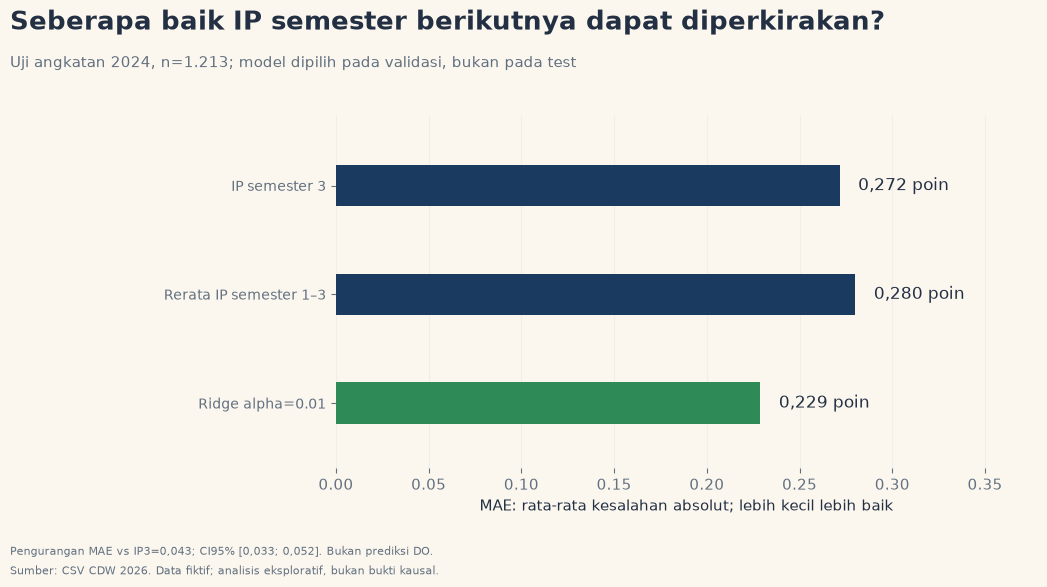

In [29]:
fig, ax = canvas('Seberapa baik IP semester berikutnya dapat diperkirakan?',
                 f'Uji angkatan {test_year}, n={jumlah(len(test))}; model dipilih pada validasi, bukan pada test', size=(12.3, 6.2))
fig.subplots_adjust(left=0.31, right=0.88)
for i, row in enumerate(performance.itertuples()):
    color = C['green'] if row.model==chosen_model_name else C['nonfg']
    ax.barh(2-i, row.mae, color=color, height=0.38)
    ax.text(row.mae+0.01, 2-i, angka(row.mae, 3)+' poin', va='center', fontsize=12)
ax.set_yticks([2, 1, 0], performance.model, fontsize=10)
ax.set_xlim(0, performance.mae.max()*1.35)
ax.set_ylim(-0.6, 2.65)
ax.set_xlabel('MAE: rata-rata kesalahan absolut; lebih kecil lebih baik')
ax.grid(axis='x', color=C['line'], alpha=0.3)
ax.set_axisbelow(True)
save_advanced(fig, '18_prediksi_ip_evaluasi_baseline',
              f'Pengurangan MAE vs IP3={angka(paired.mean(), 3)}; CI95% [{angka(improvement_ci[0], 3)}; {angka(improvement_ci[1], 3)}]. Bukan prediksi DO.')

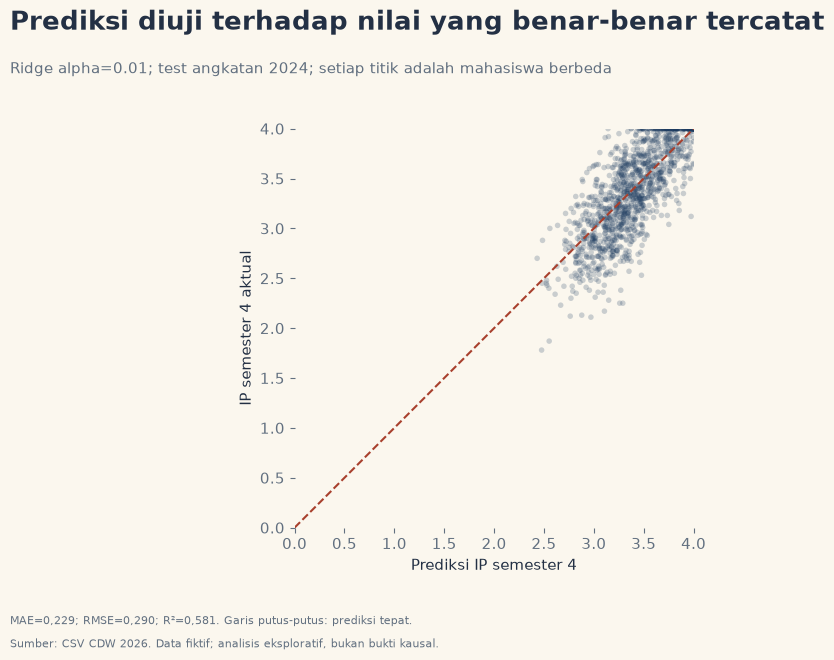

In [30]:
fig, ax = canvas('Prediksi diuji terhadap nilai yang benar-benar tercatat',
                 f'{chosen_model_name}; test angkatan {test_year}; setiap titik adalah mahasiswa berbeda', size=(10.3, 7))
ax.scatter(test.pred, test.target, s=16, alpha=0.22, color=C['nonfg'], edgecolors='none')
ax.plot([0, 4], [0, 4], color=C['risk'], ls='--', lw=1.5)
ax.set(xlim=(0, 4), ylim=(0, 4), xlabel='Prediksi IP semester 4', ylabel='IP semester 4 aktual')
ax.set_aspect('equal', adjustable='box')
save_advanced(fig, '19_prediksi_vs_aktual_ip4',
              f'MAE={angka(performance.iloc[-1].mae, 3)}; RMSE={angka(performance.iloc[-1].rmse, 3)}; R²={angka(performance.iloc[-1].r2, 3)}. Garis putus-putus: prediksi tepat.')

### Ketidakpastian dan audit kelompok
Interval split-conformal memakai residual kalibrasi yang terpisah. Target nominal 90% tidak otomatis terjamin ketika angkatan berbeda;
laporkan coverage aktual pada test. Ukuran sampel, MAE, dan coverage diperiksa per generasi pertama serta kategori ekonomi.
Ini audit kesalahan model, bukan bukti model bebas bias. Sampel interval dipilih acak, bukan berdasarkan prediksi terbaik.

,factor,group,n,mae,bias_pred_minus_actual,coverage90,mean_width
0,fg,Bukan generasi pertama,765,0.216876,0.046715,0.918954,0.861661
1,fg,Generasi pertama,448,0.249198,-0.009438,0.897321,0.935961
2,Kategori_Ekonomi,Menengah,638,0.236001,0.032196,0.905956,0.891943
3,Kategori_Ekonomi,Rendah,280,0.233083,0.007099,0.900000,0.925751
4,Kategori_Ekonomi,Tinggi,295,0.209216,0.030441,0.932203,0.848174


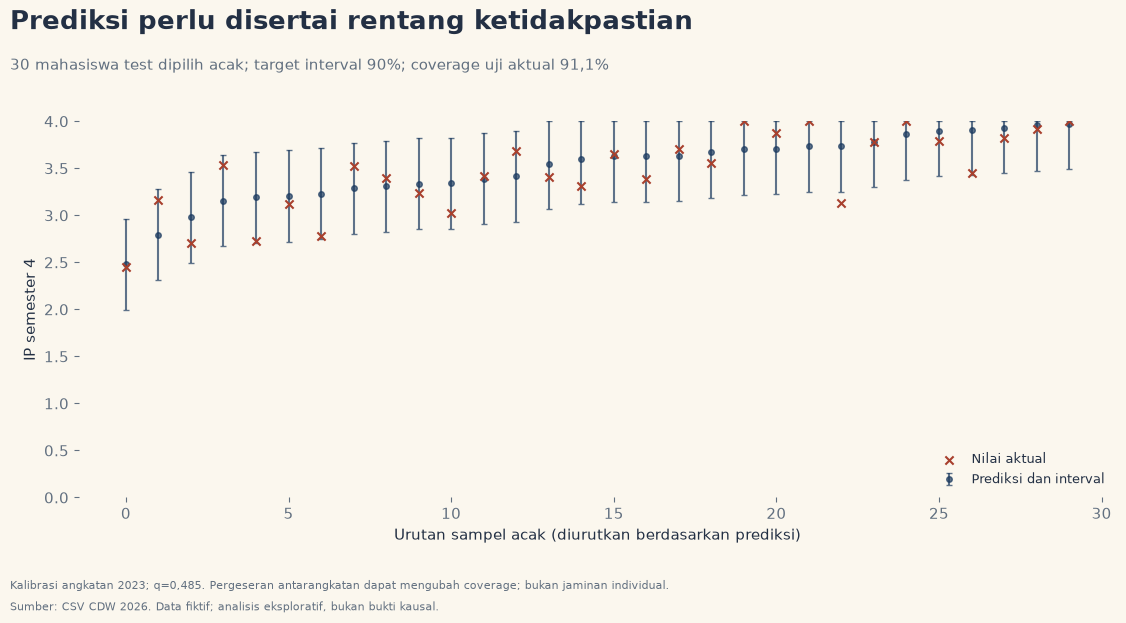

In [31]:
forecast_audit = []
for factor in ['fg', 'Kategori_Ekonomi']:
    for label, frame in test.groupby(factor, observed=True):
        title = GROUP[int(label)] if factor=='fg' else str(label)
        forecast_audit.append({'factor': factor, 'group': title, 'n': len(frame),
                               'mae': frame.absolute_error.mean(), 'bias_pred_minus_actual': (frame.pred-frame.target).mean(),
                               'coverage90': frame.covered.mean(), 'mean_width': (frame.pi_high-frame.pi_low).mean()})
forecast_audit = pd.DataFrame(forecast_audit)
export_table(forecast_audit, 'audit_prediksi_per_kelompok')
display(forecast_audit)
example = test.sample(n=min(30, len(test)), random_state=SEED).sort_values('pred').reset_index(drop=True)
fig, ax = canvas('Prediksi perlu disertai rentang ketidakpastian',
                 f'30 mahasiswa test dipilih acak; target interval 90%; coverage uji aktual {persen(test.covered.mean())}', size=(12.5, 6.6))
ax.errorbar(example.index, example.pred, yerr=[example.pred-example.pi_low, example.pi_high-example.pred],
            fmt='o', color=C['nonfg'], alpha=0.7, ms=4, capsize=2, label='Prediksi dan interval')
ax.scatter(example.index, example.target, marker='x', s=35, color=C['risk'], label='Nilai aktual', zorder=4)
ax.set(xlabel='Urutan sampel acak (diurutkan berdasarkan prediksi)', ylabel='IP semester 4', ylim=(0, 4))
ax.legend(loc='lower right', fontsize=9, frameon=False)
save_advanced(fig, '20_interval_prediksi_ip4',
              f'Kalibrasi angkatan {calibration_year}; q={angka(qhat, 3)}. Pergeseran antarangkatan dapat mengubah coverage; bukan jaminan individual.')

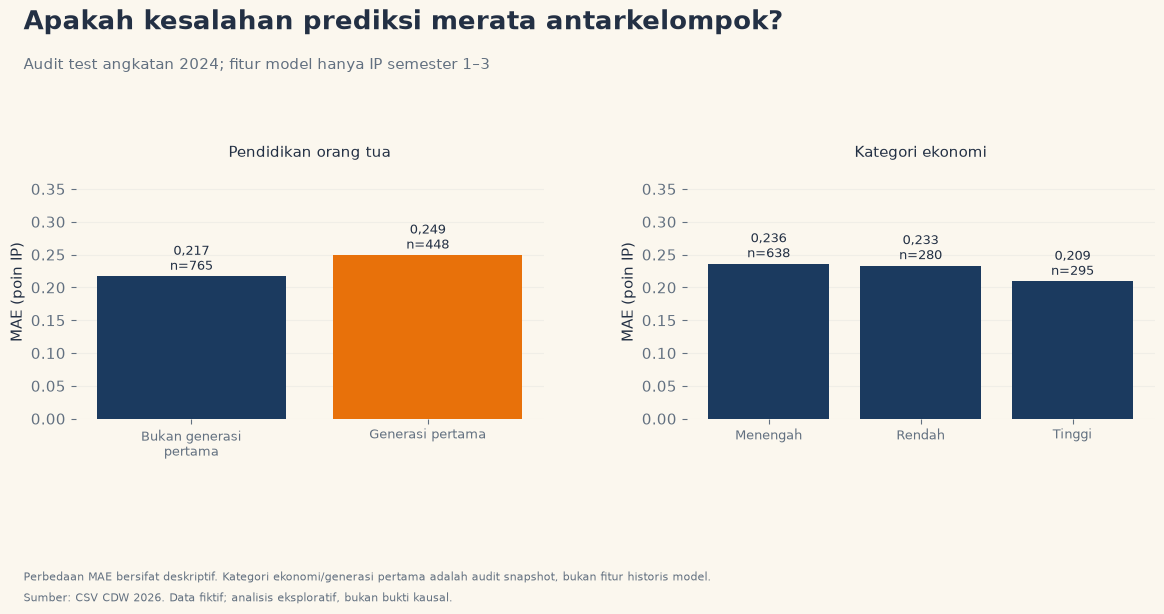

In [32]:
fig, _ = canvas('Apakah kesalahan prediksi merata antarkelompok?',
                f'Audit test angkatan {test_year}; fitur model hanya IP semester 1–3', size=(13, 6.5))
fig.axes[0].remove()
for i, factor in enumerate(['fg', 'Kategori_Ekonomi']):
    ax = fig.add_axes([0.085+i*0.47, 0.31, 0.36, 0.39])
    frame = forecast_audit.loc[forecast_audit.factor.eq(factor)].reset_index(drop=True)
    ax.bar(range(len(frame)), frame.mae, color=C['nonfg'] if i else [C['nonfg'], C['fg']])
    for j, row in frame.iterrows():
        ax.text(j, row.mae+0.01, f'{angka(row.mae, 3)}\nn={jumlah(row.n)}', ha='center', fontsize=9)
    names = [s.replace('generasi pertama', 'generasi\npertama') for s in frame.group]
    ax.set_xticks(range(len(frame)), names, fontsize=9)
    ax.set_ylim(0, forecast_audit.mae.max()*1.55)
    ax.set_ylabel('MAE (poin IP)')
    ax.set_title('Pendidikan orang tua' if factor=='fg' else 'Kategori ekonomi', fontsize=11)
    ax.grid(axis='y', alpha=0.3, color=C['line'])
    ax.set_axisbelow(True)
save_advanced(fig, '21_audit_prediksi_per_kelompok',
              'Perbedaan MAE bersifat deskriptif. Kategori ekonomi/generasi pertama adalah audit snapshot, bukan fitur historis model.')

## 17. Hasil dan batas penggunaan

Clustering membantu membaca variasi kondisi, bukan menetapkan identitas/risiko mahasiswa.
Uji interaksi memeriksa klaim penguatan pola, bukan membuktikan penyebab. Prediksi IP hanya diuji retrospektif pada data simulasi.
PETA diletakkan setelah analisis, sebagai jembatan strategi menuju JEMBATAN, bukan hasil statistik.

Referensi metode:
- [SciPy average linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [Adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)
- [Split-conformal dan exchangeability](https://arxiv.org/abs/2107.07511)

In [33]:
advanced_pdf.close()
advanced_manifest_df = pd.DataFrame(advanced_manifest)
export_table(advanced_manifest_df, 'manifest_analisis_lanjutan')
assert len(advanced_manifest_df)==9
assert not advanced_manifest_df.nama.duplicated().any()
for name in advanced_manifest_df.nama:
    for folder, ext in [('png', 'png'), ('svg', 'svg'), ('pdf', 'pdf')]:
        file = ADV / folder / f'{name}.{ext}'
        assert file.is_file() and file.stat().st_size>1000
    assert (SVG_OUT / f'{name}.svg').is_file()
results_advanced = {
    'cluster': {'features': ['ekonomi', 'bekerja', 'dukungan', 'tanggungan', 'kendala'],
                'initial_with_scholarship_k': initial_k,
                'initial_with_scholarship_quality': quality_with_sch.to_dict('records'),
                'k': chosen_k, 'silhouette': float(chosen_quality.silhouette_gower),
                'ari_median': float(chosen_quality.ari_median), 'quality_gate': bool(cluster_gate),
                'ari_with_scholarship': float(cluster_sensitivity),
                'profiles': cluster_profile.to_dict('records'), 'tests': cluster_tests.to_dict('records')},
    'interaction': interaction_tests.to_dict('records'),
    'forecast': {'chosen_model': chosen_model_name, 'split': split_info.to_dict('records'),
                 'performance': performance.to_dict('records'), 'coverage90': float(test.covered.mean()),
                 'qhat': qhat, 'mae_improvement_vs_ip3': float(paired.mean()),
                 'improvement_ci95': improvement_ci.tolist(), 'group_audit': forecast_audit.to_dict('records')},
    'versions': {'sklearn': sklearn.__version__}, 'new_visuals': len(advanced_manifest)}
with (ADV / 'Ringkasan_Analisis_Lanjutan.json').open('w', encoding='utf-8') as file:
    json.dump(results_advanced, file, ensure_ascii=False, indent=2)
with ZipFile(OUT / 'Aset_Infografis_CDW2026.zip', 'w', compression=ZIP_DEFLATED) as archive:
    for file in sorted(OUT.rglob('*')):
        if file.is_file() and file.suffix.lower() in {'.png', '.svg', '.pdf', '.csv', '.json'}:
            archive.write(file, arcname=file.relative_to(OUT))
display(advanced_manifest_df)
print(f'{len(advanced_manifest)} visual tambahan diekspor; {14+len(advanced_manifest)} visual individual tersedia bersama visual sebelumnya.')
print('SVG:', SVG_OUT)
display(FileLink(str(ADV / 'Katalog_Analisis_Lanjutan_CDW2026.pdf')))

,nama,catatan
0,14_validasi_clustering_gower,k=3; ukuran/stabilitas lolos=True; ARI menamba...
1,15_heatmap_profil_kebutuhan,*Beasiswa/generasi pertama bukan fitur cluster...
2,16_capaian_menurut_cluster,Cluster bukan label risiko. Perbedaan belum di...
3,22_cluster_kendala_finansial,Kategori ekonomi bukan satu-satunya penanda ke...
4,17_interaksi_bekerja_generasi_pertama,"Interaksi OLS=-0,028 [-0,080; 0,024]; p Holm=0..."
5,18_prediksi_ip_evaluasi_baseline,"Pengurangan MAE vs IP3=0,043; CI95% [0,033; 0,..."
6,19_prediksi_vs_aktual_ip4,"MAE=0,229; RMSE=0,290; R²=0,581. Garis putus-p..."
7,20_interval_prediksi_ip4,"Kalibrasi angkatan 2023; q=0,485. Pergeseran a..."
8,21_audit_prediksi_per_kelompok,Perbedaan MAE bersifat deskriptif. Kategori ek...


9 visual tambahan diekspor; 23 visual individual tersedia bersama visual sebelumnya.
SVG: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\svg_plot_cdw2026


C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\output_visualisasi_cdw\analisis_lanjutan\Katalog_Analisis_Lanjutan_CDW2026.pdf

## 18. Riwayat IP dan prediksi rata-rata menurut generasi pertama

Garis penuh: rerata **IP semester** 1–3. Garis putus-putus: sambungan IP3 ke rerata prediksi IP4 dari model sebelumnya.
Kedua kelompok memakai mahasiswa uji angkatan 2024 yang sama pada setiap titik: generasi pertama n=448; pembanding n=765.
Prediksi individual dihitung terlebih dahulu, baru dirata-ratakan per kelompok; status generasi pertama bukan fitur model.

Tersedia satu grafik dengan dua garis serta alternatif dua panel berskala sama. Pilih salah satu untuk infografis.
Ini pengujian retrospektif pada data simulasi, bukan forecasting semester 5–8 atau bukti sebab-akibat.
Interval prediksi individual tidak dirata-ratakan menjadi interval rata-rata kelompok. Grafik ini tidak menampilkan band ketidakpastian.
Ekspor: PNG dan SVG di `output_visualisasi_cdw/prediksi_kelompok`; SVG juga di `svg_plot_cdw2026`.

In [34]:
from matplotlib.lines import Line2D

GROUP_OUT = OUT / 'prediksi_kelompok'
for folder in ['png', 'svg', 'tabel']:
    (GROUP_OUT / folder).mkdir(parents=True, exist_ok=True)

assert test.ID_Mahasiswa.is_unique
assert test[['ip1', 'ip2', 'ip3', 'pred']].notna().all().all()
assert test.Angkatan.eq(test_year).all()
assert set(test.fg) == {0, 1}
assert np.allclose(test.pred, np.clip(predictor.predict(test[['ip1', 'ip2', 'ip3']]), 0, 4))
trajectory = test.groupby('fg', observed=True).agg(
    n=('ID_Mahasiswa', 'size'), ip1=('ip1', 'mean'), ip2=('ip2', 'mean'),
    ip3=('ip3', 'mean'), pred_ip4=('pred', 'mean'), actual_ip4=('target', 'mean')).reset_index()
trajectory['kelompok'] = trajectory.fg.map(GROUP)
assert trajectory.n.sum() == len(test)
export_trajectory = trajectory[['kelompok', 'n', 'ip1', 'ip2', 'ip3', 'pred_ip4', 'actual_ip4']].copy()
export_trajectory.to_csv(GROUP_OUT / 'tabel' / 'rerata_ip_dan_prediksi_kelompok.csv', index=False, encoding='utf-8-sig')

group_plot_names = []

def save_group_plot(fig, name):
    fig.text(0.045, 0.070, 'IP semester, bukan IPK kumulatif. Kohort tetap; prediksi individual dirata-ratakan per kelompok.', fontsize=8, color=C['muted'])
    fig.text(0.045, 0.030, 'Sumber: CSV CDW 2026. Data simulasi; evaluasi retrospektif, bukan prediksi DO.', fontsize=8, color=C['muted'])
    fig.savefig(GROUP_OUT / 'png' / f'{name}.png', dpi=DPI, bbox_inches='tight', pad_inches=0.22)
    for path in [GROUP_OUT / 'svg' / f'{name}.svg', SVG_OUT / f'{name}.svg']:
        fig.savefig(path, format='svg', bbox_inches='tight', pad_inches=0.22, transparent=True)
    group_plot_names.append(name)
    if SHOW_FIGURES:
        display(fig)
    plt.close(fig)

def draw_group_history(ax, row):
    color = COLORS[int(row.fg)]
    history = np.array([row.ip1, row.ip2, row.ip3])
    ax.plot([1, 2, 3], history, color=color, marker='o', lw=2.8, ms=6)
    ax.plot([3, 4], [row.ip3, row.pred_ip4], color=color, ls=(0, (4, 3)), lw=2.8)
    ax.scatter([4], [row.pred_ip4], facecolors=C['bg'], edgecolors=color, s=80, linewidths=2, zorder=5)
    for semester, value in enumerate([*history, row.pred_ip4], start=1):
        offset, alignment = ((0, -14), 'top') if int(row.fg) == 1 else ((0, 11), 'bottom')
        ax.annotate(angka(value, 2), (semester, value), xytext=offset, textcoords='offset points', ha='center', va=alignment, fontsize=10.5, color=C['ink'])
    ax.set_xticks([1, 2, 3, 4], ['Semester 1', 'Semester 2', 'Semester 3', 'Semester 4\n(prediksi)'])
    ax.set(xlim=(0.80, 4.30), ylim=(0, 4.10), ylabel='Rata-rata IP semester (skala 0–4)')
    ax.set_yticks(np.arange(0, 4.1, 0.5))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: angka(value, 1)))
    ax.axvspan(3.5, 4.30, color=C['ink'], alpha=0.035, zorder=0)
    ax.grid(axis='y', color=C['line'], alpha=0.45)
    ax.set_axisbelow(True)

display(export_trajectory.round(3))

,kelompok,n,ip1,ip2,ip3,pred_ip4,actual_ip4
0,Bukan generasi pertama,765,3.136,3.314,3.445,3.478,3.432
1,Generasi pertama,448,2.676,2.978,3.213,3.230,3.239


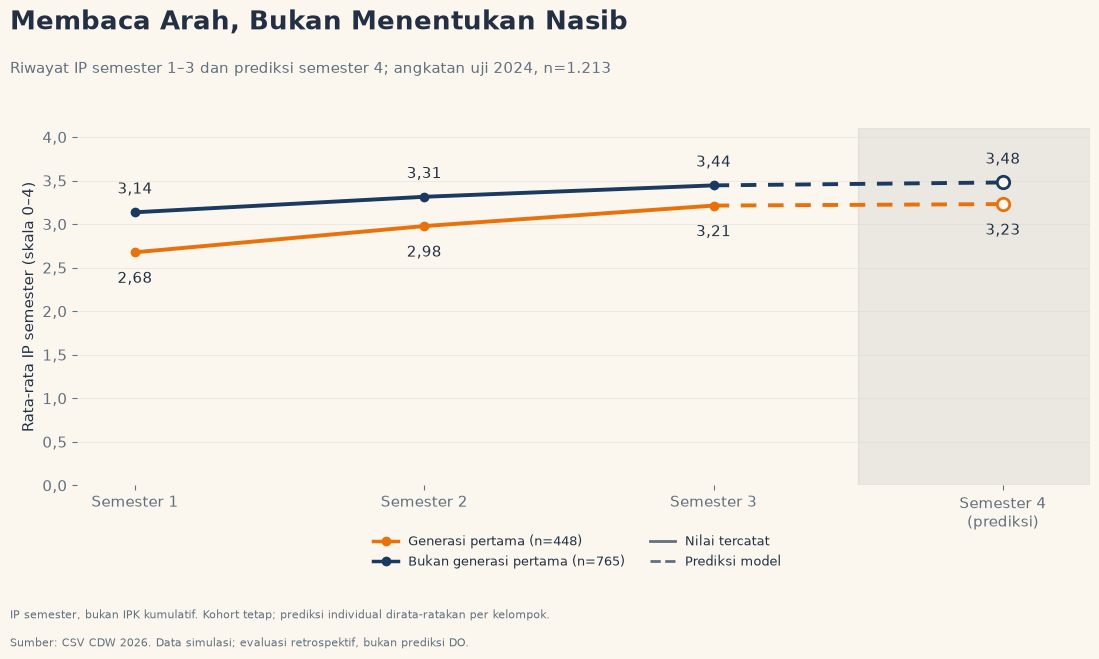

In [35]:
fig, ax = canvas('Membaca Arah, Bukan Menentukan Nasib',
                 f'Riwayat IP semester 1–3 dan prediksi semester 4; angkatan uji {test_year}, n={jumlah(len(test))}', size=(12.2, 7.0), bottom=0.26)
for row in trajectory.itertuples():
    draw_group_history(ax, row)
handles = [
    Line2D([0], [0], color=COLORS[fg], marker='o', lw=2.5,
           label=f'{GROUP[fg]} (n={jumlah(trajectory.loc[trajectory.fg.eq(fg), "n"].iloc[0])})') for fg in [1, 0]
]+[
    Line2D([0], [0], color=C['muted'], lw=2, label='Nilai tercatat'),
    Line2D([0], [0], color=C['muted'], lw=2, ls='--', label='Prediksi model')
]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.51, 0.125), ncol=2, fontsize=9, frameon=False)
save_group_plot(fig, '23_lintasan_ip_prediksi_dua_kelompok')

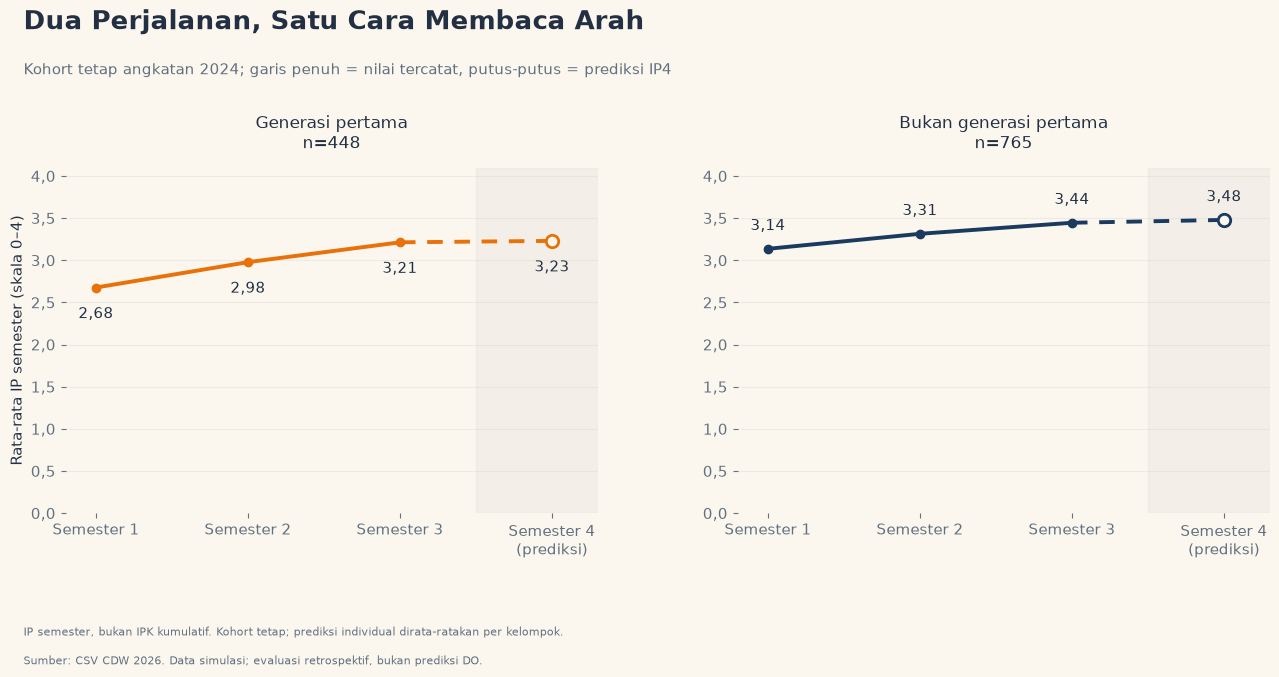

In [36]:
fig, _ = canvas('Dua Perjalanan, Satu Cara Membaca Arah',
                f'Kohort tetap angkatan {test_year}; garis penuh = nilai tercatat, putus-putus = prediksi IP4', size=(14.0, 7.2), bottom=0.24)
fig.axes[0].remove()
for i, fg in enumerate([1, 0]):
    row = next(r for r in trajectory.itertuples() if r.fg == fg)
    ax = fig.add_axes([0.075+i*0.48, 0.24, 0.38, 0.48])
    draw_group_history(ax, row)
    ax.set_title(f'{GROUP[fg]}\nn={jumlah(row.n)}', fontsize=12, pad=14)
    if i==1:
        ax.set_ylabel('')
save_group_plot(fig, '24_lintasan_ip_prediksi_panel_kelompok')

In [37]:
assert len(group_plot_names) == 2
for name in group_plot_names:
    assert (GROUP_OUT / 'png' / f'{name}.png').is_file()
    assert (GROUP_OUT / 'svg' / f'{name}.svg').is_file()
    assert (SVG_OUT / f'{name}.svg').is_file()
assert 'ID_Mahasiswa' not in export_trajectory.columns
with ZipFile(OUT / 'Aset_Infografis_CDW2026.zip', 'w', compression=ZIP_DEFLATED) as archive:
    for file in sorted(OUT.rglob('*')):
        if file.is_file() and file.suffix.lower() in {'.png', '.svg', '.pdf', '.csv', '.json'}:
            archive.write(file, arcname=file.relative_to(OUT))
print('Dua alternatif lintasan kelompok tersimpan; prediksi hanya semester 4.')
print('SVG:', SVG_OUT)

Dua alternatif lintasan kelompok tersimpan; prediksi hanya semester 4.
SVG: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK\svg_plot_cdw2026
